In [3]:

import requests
import zipfile
from pathlib import Path

record_id = "15797402"
api_url = f"https://zenodo.org/api/records/{record_id}"

response = requests.get(api_url, timeout=30)
response.raise_for_status()
record = response.json()

rabi_file = next(
    (f for f in record["files"] if f["key"] == "Rabi.zip"),
    None
)

if rabi_file is None:
    raise FileNotFoundError(
        "Rabi.zip was not found in the Zenodo record."
    )

download_url = (
    rabi_file["links"].get("download")
    or f"https://zenodo.org/records/{record_id}/files/Rabi.zip?download=1"
)

zip_path = Path("/content/Rabi.zip")

with requests.get(download_url, stream=True, timeout=60) as r:
    r.raise_for_status()
    with open(zip_path, "wb") as file:
        for chunk in r.iter_content(chunk_size=1024 * 1024):
            if chunk:
                file.write(chunk)

if not zipfile.is_zipfile(zip_path):
    raise ValueError("Downloaded file is not a valid ZIP archive.")

data_dir = Path("/content/rabi_data")
data_dir.mkdir(exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as archive:
    archive.extractall(data_dir)
    files = [
        name for name in archive.namelist()
        if not name.endswith("/")
    ]


print(f"Number of files: {len(files)}")
print("\nFirst 15 files:")

for name in files[:15]:
    print(name)


Number of files: 63

First 15 files:
Rabi/0+1/0.1_ms.xlsx
Rabi/0+1/0.2_ms.xlsx
Rabi/0+1/0.5_ms.xlsx
Rabi/0+1/10_ms.xlsx
Rabi/0+1/120_ms.xlsx
Rabi/0+1/1_ms.xlsx
Rabi/0+1/20_ms.xlsx
Rabi/0+1/2_ms.xlsx
Rabi/0+1/40_ms.xlsx
Rabi/0+1/5_ms.xlsx
Rabi/0+1/80_ms.xlsx
Rabi/0+2/0.1_ms.xlsx
Rabi/0+3/0.1ms.xlsx
Rabi/0+3/0.2ms.xlsx
Rabi/0+3/0.5ms.xlsx


In [4]:

from pathlib import Path
import pandas as pd

data_dir = Path("/content/rabi_data")

wanted = [
    "Rabi/0+1/0.1_ms.xlsx",
    "Rabi/0+1/10_ms.xlsx",
    "Rabi/0+2/0.1_ms.xlsx",
    "Rabi/0+3/0.1ms.xlsx",
]

for relative_path in wanted:
    file_path = data_dir / relative_path

    print("FILE:", relative_path)

    if not file_path.exists():
        print("File not found — checking available matches...")
        matches = list(data_dir.rglob(file_path.name))
        if not matches:
            print("No matching file found.")
            continue
        file_path = matches[0]
        print("Using:", file_path.relative_to(data_dir))

    excel_file = pd.ExcelFile(file_path)
    print("Sheets:", excel_file.sheet_names)

    for sheet in excel_file.sheet_names[:2]:
        df = pd.read_excel(file_path, sheet_name=sheet)

        print(f"\nSheet: {sheet}")
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.head(5).to_string(index=False))


FILE: Rabi/0+1/0.1_ms.xlsx
Sheets: ['Sheet1']

Sheet: Sheet1
Shape: (487, 2)
Columns: ['Time, s', 'Probability']
     Time, s  Probability
1.000000e-08         0.00
5.010000e-06         0.01
1.001000e-05         0.00
1.501000e-05         0.01
2.001000e-05         0.03
FILE: Rabi/0+1/10_ms.xlsx
Sheets: ['Sheet1']

Sheet: Sheet1
Shape: (449, 2)
Columns: ['Time, s', 'Probability']
     Time, s  Probability
1.000000e-08         0.00
5.010000e-06         0.00
1.001000e-05         0.00
1.501000e-05         0.00
2.001000e-05         0.03
FILE: Rabi/0+2/0.1_ms.xlsx
Sheets: ['Sheet1']

Sheet: Sheet1
Shape: (593, 2)
Columns: ['Time, s', 'Probability']
     Time, s  Probability
1.000000e-08         0.01
5.010000e-06         0.01
1.001000e-05         0.00
1.501000e-05         0.02
2.001000e-05         0.02
FILE: Rabi/0+3/0.1ms.xlsx
Sheets: ['Sheet1']

Sheet: Sheet1
Shape: (623, 2)
Columns: ['Time, s', 'Probability']
     Time, s  Probability
1.000000e-08         0.00
2.500000e-05         0.00
2.50

In [5]:

from pathlib import Path

import pandas as pd

data_dir = Path("/content/rabi_data")
data_files = sorted(data_dir.rglob("*.xlsx"))

results = []

for file_path in data_files:
    data = pd.read_excel(file_path)

    time = data["Time, s"]
    probability = data["Probability"]

    results.append({
        "file": str(file_path.relative_to(data_dir)),
        "rows": len(data),
        "missing_values": data.isna().sum().sum(),
        "duplicate_times": time.duplicated().sum(),
        "min_time_s": time.min(),
        "max_time_s": time.max(),
        "min_probability": probability.min(),
        "max_probability": probability.max(),
        "out_of_range": (
            (probability.dropna() < 0)
            | (probability.dropna() > 1)
        ).sum()
    })

summary = pd.DataFrame(results)

print(f"Files checked: {len(summary)}")
print(f"Total measurements: {summary['rows'].sum():,}")
print(f"Files with missing values: {(summary['missing_values'] > 0).sum()}")
print(f"Files with duplicate timestamps: {(summary['duplicate_times'] > 0).sum()}")
print(f"Files with probabilities outside [0, 1]: {(summary['out_of_range'] > 0).sum()}")

display(summary.head(10))
display(summary.describe().round(6))


Files checked: 63
Total measurements: 42,054
Files with missing values: 0
Files with duplicate timestamps: 17
Files with probabilities outside [0, 1]: 0


,file,rows,missing_values,duplicate_times,min_time_s,max_time_s,min_probability,max_probability,out_of_range
0,Rabi/0+1/0.1_ms.xlsx,487,0,0,1.000000e-08,0.002430,0.0,0.96,0
1,Rabi/0+1/0.2_ms.xlsx,543,0,0,1.000000e-08,0.002710,0.0,0.95,0
2,Rabi/0+1/0.5_ms.xlsx,494,0,1,1.000000e-08,0.002460,0.0,0.96,0
3,Rabi/0+1/10_ms.xlsx,449,0,0,1.000000e-08,0.002240,0.0,0.91,0
4,Rabi/0+1/120_ms.xlsx,2694,0,0,1.000000e-08,0.013465,0.0,1.00,0
5,Rabi/0+1/1_ms.xlsx,748,0,0,1.000000e-08,0.003735,0.0,1.00,0
6,Rabi/0+1/20_ms.xlsx,466,0,0,1.000000e-08,0.002325,0.0,0.89,0
7,Rabi/0+1/2_ms.xlsx,461,0,3,1.000000e-08,0.002285,0.0,0.94,0
8,Rabi/0+1/40_ms.xlsx,1254,0,0,1.000000e-08,0.006265,0.0,1.00,0
9,Rabi/0+1/5_ms.xlsx,452,0,0,1.000000e-08,0.002255,0.0,0.91,0


,rows,missing_values,duplicate_times,min_time_s,max_time_s,min_probability,max_probability,out_of_range
count,63.000000,63.0,63.000000,63.0,63.000000,63.000000,63.000000,63.0
mean,667.523810,0.0,0.301587,0.0,0.003714,0.005079,0.921111,0.0
std,796.420153,0.0,0.557498,0.0,0.003995,0.011053,0.067945,0.0
min,286.000000,0.0,0.000000,0.0,0.001515,0.000000,0.790000,0.0
25%,399.000000,0.0,0.000000,0.0,0.002248,0.000000,0.870000,0.0
50%,461.000000,0.0,0.000000,0.0,0.002460,0.000000,0.940000,0.0
75%,538.000000,0.0,1.000000,0.0,0.003738,0.000000,0.980000,0.0
max,5791.000000,0.0,3.000000,0.0,0.029430,0.040000,1.000000,0.0


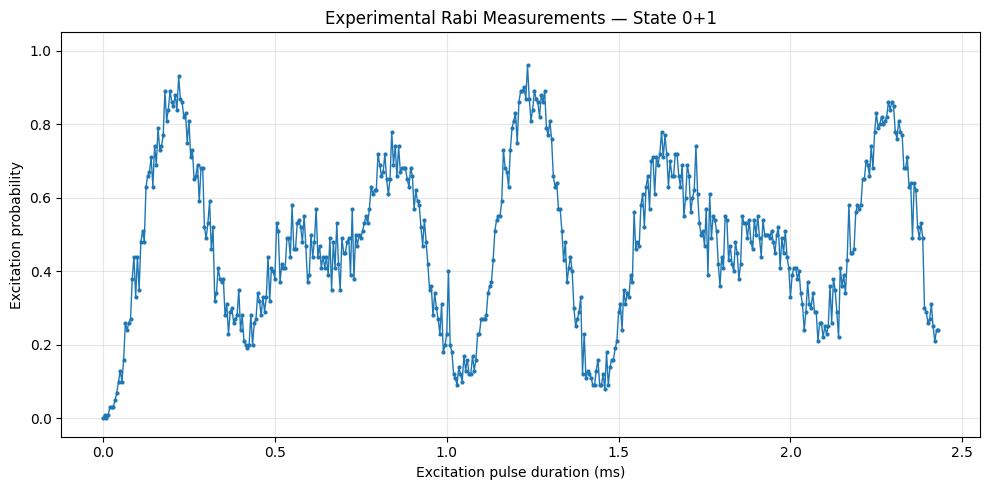

Measurements: 487
Time range: 0.0000 to 2.4300 ms
Unique time values: 487


In [6]:

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

file_path = Path("/content/rabi_data/Rabi/0+1/0.1_ms.xlsx")

data = pd.read_excel(file_path)
data = data.sort_values("Time, s")

data["Time (ms)"] = data["Time, s"] * 1_000

plt.figure(figsize=(10, 5))

plt.plot(
    data["Time (ms)"],
    data["Probability"],
    marker=".",
    markersize=4,
    linewidth=1
)

plt.xlabel("Excitation pulse duration (ms)")
plt.ylabel("Excitation probability")
plt.title("Experimental Rabi Measurements — State 0+1")
plt.ylim(-0.05, 1.05)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Measurements: {len(data)}")
print(f"Time range: {data['Time (ms)'].min():.4f} to "
      f"{data['Time (ms)'].max():.4f} ms")
print(f"Unique time values: {data['Time, s'].nunique()}")


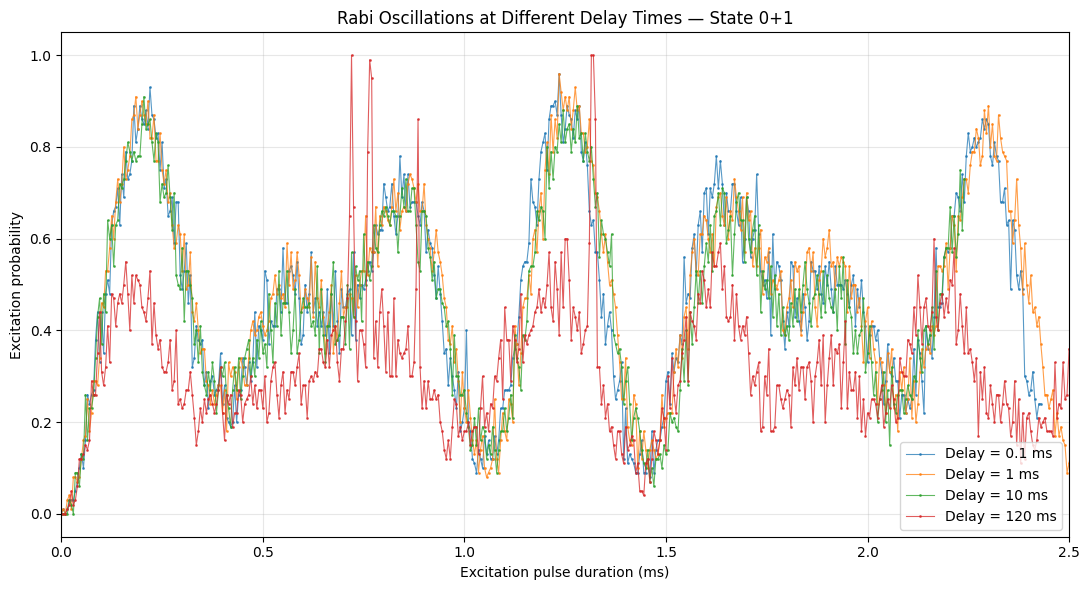

In [7]:

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

data_dir = Path("/content/rabi_data/Rabi/0+1")

delay_times = ["0.1", "1", "10", "120"]

plt.figure(figsize=(11, 6))

for delay in delay_times:
    file_path = data_dir / f"{delay}_ms.xlsx"
    data = pd.read_excel(file_path)
    data = data.sort_values("Time, s")

    pulse_duration_ms = data["Time, s"] * 1_000

    plt.plot(
        pulse_duration_ms,
        data["Probability"],
        marker=".",
        markersize=2,
        linewidth=0.8,
        alpha=0.75,
        label=f"Delay = {delay} ms"
    )

plt.xlim(0, 2.5)
plt.ylim(-0.05, 1.05)
plt.xlabel("Excitation pulse duration (ms)")
plt.ylabel("Excitation probability")
plt.title("Rabi Oscillations at Different Delay Times — State 0+1")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [8]:

from pathlib import Path

import pandas as pd

data_dir = Path("/content/rabi_data/Rabi/0+1")
delay_times = ["0.1", "1", "10", "120"]

summary = []

for delay in delay_times:
    file_path = data_dir / f"{delay}_ms.xlsx"
    data = pd.read_excel(file_path)

    pulse_time = data["Time, s"]
    probability = data["Probability"]

    summary.append({
        "Rabi delay (ms)": float(delay),
        "Measurements": len(data),
        "Unique pulse times": pulse_time.nunique(),
        "Duplicate timestamps": pulse_time.duplicated().sum(),
        "Pulse duration (ms)": pulse_time.max() * 1_000,
        "Mean probability": probability.mean(),
        "Probability SD": probability.std(),
        "Minimum probability": probability.min(),
        "Maximum probability": probability.max()
    })

summary = pd.DataFrame(summary)

display(summary.round(4))


,Rabi delay (ms),Measurements,Unique pulse times,Duplicate timestamps,Pulse duration (ms),Mean probability,Probability SD,Minimum probability,Maximum probability
0,0.1,487,487,0,2.430,0.4806,0.2160,0.0,0.96
1,1.0,748,748,0,3.735,0.4820,0.2075,0.0,1.00
2,10.0,449,449,0,2.240,0.4514,0.2014,0.0,0.91
3,120.0,2694,2694,0,13.465,0.3420,0.1173,0.0,1.00


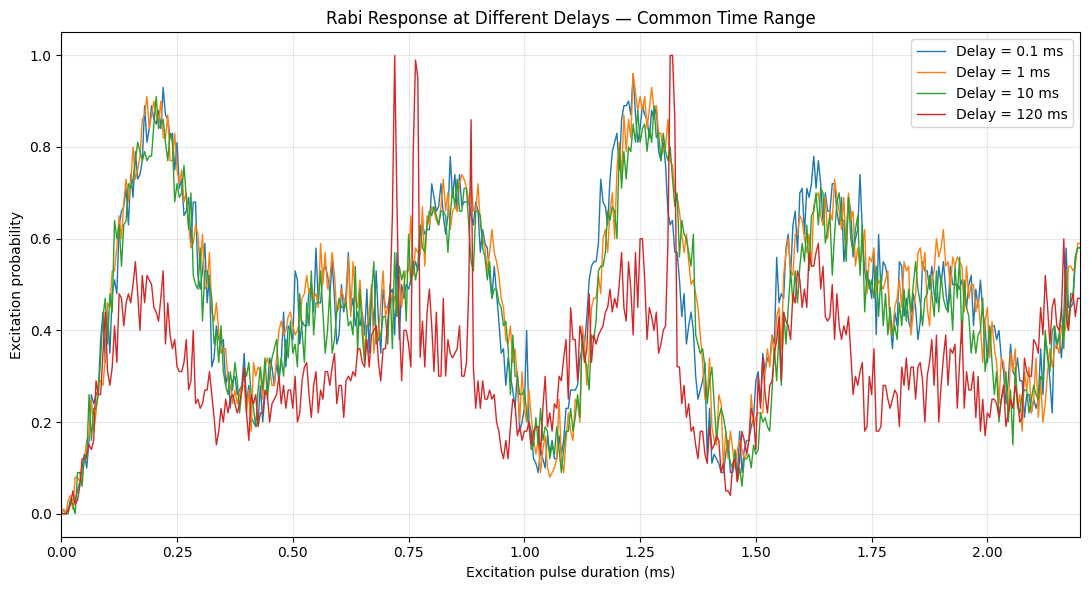

,Rabi delay (ms),Measurements in range,Mean probability,Probability SD
0,0.1,440,0.4658,0.2117
1,1.0,440,0.4734,0.2088
2,10.0,440,0.4479,0.2010
3,120.0,440,0.3228,0.1467


In [9]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data_dir = Path("/content/rabi_data/Rabi/0+1")
delay_times = ["0.1", "1", "10", "120"]

common_time = np.linspace(0, 2.2, 441)
comparison_results = []

plt.figure(figsize=(11, 6))

for delay in delay_times:
    file_path = data_dir / f"{delay}_ms.xlsx"
    data = pd.read_excel(file_path)

    data["Pulse time (ms)"] = data["Time, s"] * 1_000
    data = data.sort_values("Pulse time (ms)")

    data = data[data["Pulse time (ms)"] <= 2.2]

    probability = np.interp(
        common_time,
        data["Pulse time (ms)"],
        data["Probability"]
    )

    comparison_results.append({
        "Rabi delay (ms)": float(delay),
        "Measurements in range": len(data),
        "Mean probability": probability.mean(),
        "Probability SD": probability.std()
    })

    plt.plot(
        common_time,
        probability,
        linewidth=1,
        label=f"Delay = {delay} ms"
    )

plt.xlabel("Excitation pulse duration (ms)")
plt.ylabel("Excitation probability")
plt.title("Rabi Response at Different Delays — Common Time Range")
plt.xlim(0, 2.2)
plt.ylim(-0.05, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

comparison = pd.DataFrame(comparison_results)
display(comparison.round(4))


In [10]:

from pathlib import Path
import zipfile
import requests

record_id = "15797402"
api_url = f"https://zenodo.org/api/records/{record_id}"

response = requests.get(api_url, timeout=30)
response.raise_for_status()
metadata = response.json()

ramsey_file = next(
    (
        file for file in metadata.get("files", [])
        if file.get("key") == "Ramsey.zip"
    ),
    None
)

if ramsey_file is None:
    raise FileNotFoundError(
        "Ramsey.zip was not found in the Zenodo record."
    )

download_url = (
    ramsey_file.get("links", {}).get("content")
    or f"https://zenodo.org/records/{record_id}/files/Ramsey.zip?download=1"
)

zip_path = Path("/content/Ramsey.zip")

with requests.get(download_url, stream=True, timeout=60) as response:
    response.raise_for_status()

    with open(zip_path, "wb") as output:
        for chunk in response.iter_content(chunk_size=1024 * 1024):
            if chunk:
                output.write(chunk)

if not zipfile.is_zipfile(zip_path):
    raise ValueError(
        "The downloaded file is not a valid ZIP archive."
    )

ramsey_dir = Path("/content/ramsey_data")
ramsey_dir.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as archive:
    archive.extractall(ramsey_dir)
    files = [
        name for name in archive.namelist()
        if not name.endswith("/")
    ]

print("Ramsey dataset downloaded and verified!")
print(f"Number of files: {len(files)}")
print("\nFirst 25 files:")

for name in files[:25]:
    print(name)


Ramsey dataset downloaded and verified!
Number of files: 177

First 25 files:
Ramsey/0+1/step_2_delay_0.1_ms.xlsx
Ramsey/0+1/step_2_delay_0.2_ms.xlsx
Ramsey/0+1/step_2_delay_0.5_ms.xlsx
Ramsey/0+1/step_2_delay_10_ms.xlsx
Ramsey/0+1/step_2_delay_120_ms.xlsx
Ramsey/0+1/step_2_delay_1_ms.xlsx
Ramsey/0+1/step_2_delay_20_ms.xlsx
Ramsey/0+1/step_2_delay_2_ms.xlsx
Ramsey/0+1/step_2_delay_40_ms.xlsx
Ramsey/0+1/step_2_delay_5_ms.xlsx
Ramsey/0+1/step_2_delay_80_ms.xlsx
Ramsey/0+2/step_2_delay_0.1_ms.xlsx
Ramsey/0+2/step_2_delay_0.2_ms.xlsx
Ramsey/0+2/step_2_delay_0.5_ms.xlsx
Ramsey/0+2/step_2_delay_10_ms.xlsx
Ramsey/0+2/step_2_delay_1_ms.xlsx
Ramsey/0+2/step_2_delay_20_ms.xlsx
Ramsey/0+2/step_2_delay_2_ms.xlsx
Ramsey/0+2/step_2_delay_5_ms_(1).xlsx
Ramsey/0+2/step_2_delay_5_ms_(2).xlsx
Ramsey/0+2/step_2_delay_80_ms.xlsx
Ramsey/0+3/step_1_delay_0.1_ms_repetitions_25_(0).xlsx
Ramsey/0+3/step_1_delay_0.1_ms_repetitions_25_(1).xlsx
Ramsey/0+3/step_1_delay_0.1_ms_repetitions_25_(2).xlsx
Ramsey/0+3/ste

In [11]:

from pathlib import Path

import pandas as pd

data_dir = Path("/content/ramsey_data")

files_to_inspect = [
    "Ramsey/0+1/step_2_delay_0.1_ms.xlsx",
    "Ramsey/0+1/step_2_delay_120_ms.xlsx",
    "Ramsey/0+3/step_1_delay_0.1_ms_repetitions_25_(0).xlsx",
]

for relative_path in files_to_inspect:
    file_path = data_dir / relative_path

    print(f"File: {relative_path}")

    if not file_path.exists():
        print("File not found.")
        continue

    workbook = pd.ExcelFile(file_path)
    print("Sheets:", workbook.sheet_names)

    for sheet_name in workbook.sheet_names:
        data = pd.read_excel(file_path, sheet_name=sheet_name)

        print(f"\nSheet: {sheet_name}")
        print("Shape:", data.shape)
        print("Columns:", data.columns.tolist())
        print(data.head(5).to_string(index=False))


File: Ramsey/0+1/step_2_delay_0.1_ms.xlsx
Sheets: ['Sheet1']

Sheet: Sheet1
Shape: (193, 1)
Columns: ['probability']
 probability
        0.14
        0.09
        0.09
        0.05
        0.02
File: Ramsey/0+1/step_2_delay_120_ms.xlsx
Sheets: ['Sheet1']

Sheet: Sheet1
Shape: (181, 1)
Columns: ['probability']
 probability
        0.35
        0.39
        0.31
        0.27
        0.22
File: Ramsey/0+3/step_1_delay_0.1_ms_repetitions_25_(0).xlsx
Sheets: ['Sheet1']

Sheet: Sheet1
Shape: (361, 1)
Columns: ['probability']
 probability
        0.64
        0.56
        0.64
        0.52
        0.72


In [12]:

from pathlib import Path
import re

import pandas as pd

DATA_DIR = Path("/content/ramsey_data")

FILE_PATTERN = re.compile(
    r"step_(?P<phase_step>\d+)"
    r"_delay_(?P<delay_ms>[\d.]+)_ms"
    r"(?:_repetitions_(?P<repetitions>\d+)_\((?P<repeat_index>\d+)\))?"
    r"\.xlsx$"
)

records = []
unmatched_files = []

for file_path in sorted(DATA_DIR.rglob("*.xlsx")):
    match = FILE_PATTERN.fullmatch(file_path.name)

    if match is None:
        unmatched_files.append(str(file_path.relative_to(DATA_DIR)))
        continue

    data = pd.read_excel(file_path)
    probability = pd.to_numeric(
        data.iloc[:, 0],
        errors="coerce"
    )

    records.append({
        "state": file_path.parent.name,
        "file": file_path.name,
        "phase_step": int(match["phase_step"]),
        "delay_ms": float(match["delay_ms"]),
        "repetitions": (
            int(match["repetitions"])
            if match["repetitions"] is not None
            else 100
        ),
        "measurements": len(data),
        "missing_values": probability.isna().sum(),
        "min_probability": probability.min(),
        "max_probability": probability.max(),
    })

ramsey_audit = pd.DataFrame(records)

print(f"Files successfully inspected: {len(ramsey_audit)}")
print(f"Files with unrecognized names: {len(unmatched_files)}")

print("\nSummary by phase-step setting:")

summary = (
    ramsey_audit
    .groupby("phase_step")
    .agg(
        files=("file", "count"),
        minimum_points=("measurements", "min"),
        median_points=("measurements", "median"),
        maximum_points=("measurements", "max"),
        files_with_missing_values=(
            "missing_values",
            lambda values: (values > 0).sum()
        )
    )
    .reset_index()
)

display(summary)

print("\nMost common measurement counts for each setting:")

row_counts = (
    ramsey_audit
    .groupby(["phase_step", "measurements"])
    .size()
    .reset_index(name="number_of_files")
    .sort_values(
        ["phase_step", "number_of_files"],
        ascending=[True, False]
    )
)

display(
    row_counts
    .groupby("phase_step", group_keys=False)
    .head(8)
    .reset_index(drop=True)
)

print("\nExample file metadata:")
display(ramsey_audit.head(10))

if unmatched_files:
    print("\nFirst unmatched filenames:")
    for filename in unmatched_files[:10]:
        print(filename)


Files successfully inspected: 132
Files with unrecognized names: 45

Summary by phase-step setting:


,phase_step,files,minimum_points,median_points,maximum_points,files_with_missing_values
0,1,40,205,362.0,511,0
1,2,92,160,183.0,392,0



Most common measurement counts for each setting:


,phase_step,measurements,number_of_files
0,1,361,8
1,1,359,3
2,1,360,3
3,1,362,3
4,1,363,3
5,1,364,3
6,1,366,2
7,1,371,2
8,2,182,23
9,2,183,12



Example file metadata:


,state,file,phase_step,delay_ms,repetitions,measurements,missing_values,min_probability,max_probability
0,0+1,step_2_delay_0.1_ms.xlsx,2,0.1,100,193,0,0.00,0.98
1,0+1,step_2_delay_0.2_ms.xlsx,2,0.2,100,182,0,0.01,0.98
2,0+1,step_2_delay_0.5_ms.xlsx,2,0.5,100,183,0,0.00,0.98
3,0+1,step_2_delay_10_ms.xlsx,2,10.0,100,180,0,0.01,0.93
4,0+1,step_2_delay_120_ms.xlsx,2,120.0,100,181,0,0.16,0.59
5,0+1,step_2_delay_1_ms.xlsx,2,1.0,100,181,0,0.00,0.99
6,0+1,step_2_delay_20_ms.xlsx,2,20.0,100,182,0,0.06,0.97
7,0+1,step_2_delay_2_ms.xlsx,2,2.0,100,183,0,0.01,0.99
8,0+1,step_2_delay_40_ms.xlsx,2,40.0,100,182,0,0.09,0.77
9,0+1,step_2_delay_5_ms.xlsx,2,5.0,100,181,0,0.04,0.97



First unmatched filenames:
Ramsey/0+2/step_2_delay_5_ms_(1).xlsx
Ramsey/0+2/step_2_delay_5_ms_(2).xlsx
Ramsey/1+2/step_2_delay_0.1_ms_(0).xlsx
Ramsey/1+2/step_2_delay_0.2_ms_(0).xlsx
Ramsey/1+2/step_2_delay_0.5_ms_(0).xlsx
Ramsey/1+2/step_2_delay_100_ms_(0).xlsx
Ramsey/1+2/step_2_delay_10_ms_(0).xlsx
Ramsey/1+2/step_2_delay_15_ms_(0).xlsx
Ramsey/1+2/step_2_delay_1_ms_(0).xlsx
Ramsey/1+2/step_2_delay_1_ms_(1).xlsx


In [13]:

from pathlib import Path
import re

import pandas as pd

DATA_DIR = Path("/content/ramsey_data")

filename_pattern = re.compile(
    r"step_(?P<step>\d+)"
    r"_delay_(?P<delay_ms>[\d.]+)_ms"
    r"(?:_repetitions_(?P<repetitions>\d+))?"
    r"(?:_\((?P<repeat_index>\d+)\))?"
    r"\.xlsx$"
)

records = []
unmatched_files = []

excel_files = sorted(DATA_DIR.rglob("*.xlsx"))

for file_path in excel_files:
    match = filename_pattern.fullmatch(file_path.name)

    if match is None:
        unmatched_files.append(file_path.relative_to(DATA_DIR))
        continue

    data = pd.read_excel(file_path)

    if "probability" not in data.columns:
        unmatched_files.append(file_path.relative_to(DATA_DIR))
        continue

    probability = pd.to_numeric(
        data["probability"],
        errors="coerce"
    )

    valid_values = probability.dropna()

    records.append({
        "state": file_path.parent.name,
        "file": file_path.name,
        "phase_step": int(match["step"]),
        "delay_ms": float(match["delay_ms"]),
        "repetitions": (
            int(match["repetitions"])
            if match["repetitions"] is not None
            else 100
        ),
        "repeat_index": (
            int(match["repeat_index"])
            if match["repeat_index"] is not None
            else None
        ),
        "measurements": len(data),
        "missing_values": probability.isna().sum(),
        "out_of_range": (
            (valid_values < 0) | (valid_values > 1)
        ).sum(),
        "min_probability": valid_values.min(),
        "max_probability": valid_values.max()
    })

audit = pd.DataFrame(records)

print(f"Excel files found: {len(excel_files)}")
print(f"Files successfully inspected: {len(audit)}")
print(f"Files needing review: {len(unmatched_files)}")

if not audit.empty:
    print("\nData quality summary:")

    quality_summary = pd.DataFrame({
        "Metric": [
            "Total measurement rows",
            "Files with missing values",
            "Files with probabilities outside [0, 1]",
            "Files with zero valid measurements"
        ],
        "Value": [
            audit["measurements"].sum(),
            (audit["missing_values"] > 0).sum(),
            (audit["out_of_range"] > 0).sum(),
            audit["min_probability"].isna().sum()
        ]
    })

    display(quality_summary)

    print("\nMeasurement counts by phase-step setting:")

    step_summary = (
        audit.groupby("phase_step")
        .agg(
            files=("file", "count"),
            minimum_points=("measurements", "min"),
            median_points=("measurements", "median"),
            maximum_points=("measurements", "max")
        )
        .reset_index()
    )

    display(step_summary)

if unmatched_files:
    print("\nFirst 15 files that need review:")

    for file_path in unmatched_files[:15]:
        print(file_path)


Excel files found: 177
Files successfully inspected: 177
Files needing review: 0

Data quality summary:


,Metric,Value
0,Total measurement rows,40787
1,Files with missing values,0
2,"Files with probabilities outside [0, 1]",0
3,Files with zero valid measurements,0



Measurement counts by phase-step setting:


,phase_step,files,minimum_points,median_points,maximum_points
0,1,40,205,362.0,511
1,2,137,84,183.0,392


Measurements: 181
Phase increment: 2 degrees
Nominal phase range: 0 to 360 degrees


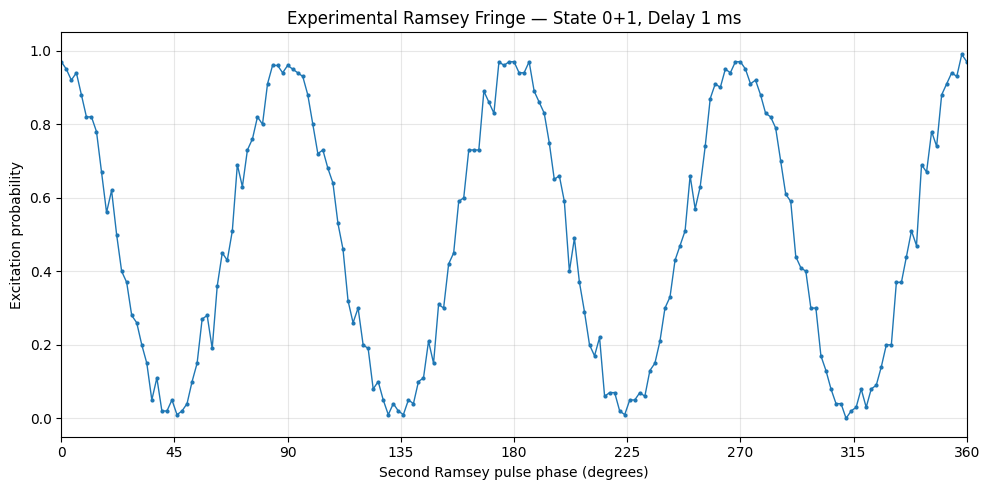

In [14]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

file_path = Path(
    "/content/ramsey_data/Ramsey/0+1/step_2_delay_1_ms.xlsx"
)

data = pd.read_excel(file_path)

if "probability" not in data.columns:
    raise ValueError("The expected 'probability' column is missing.")

probability = pd.to_numeric(
    data["probability"],
    errors="raise"
).reset_index(drop=True)

if probability.isna().any():
    raise ValueError("Missing probability values were found.")

phase_step_degrees = 2
phase_degrees = np.arange(len(probability)) * phase_step_degrees

print(f"Measurements: {len(probability)}")
print(f"Phase increment: {phase_step_degrees} degrees")
print(
    f"Nominal phase range: "
    f"{phase_degrees.min()} to {phase_degrees.max()} degrees"
)

plt.figure(figsize=(10, 5))

plt.plot(
    phase_degrees,
    probability,
    marker=".",
    markersize=4,
    linewidth=1
)

plt.xlabel("Second Ramsey pulse phase (degrees)")
plt.ylabel("Excitation probability")
plt.title("Experimental Ramsey Fringe — State 0+1, Delay 1 ms")
plt.xlim(0, 360)
plt.ylim(-0.05, 1.05)
plt.xticks(np.arange(0, 361, 45))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Measurements: 181
Best cycle count among tested models: 4
Fitted offset: 0.4906
Fitted sinusoidal amplitude: 0.4732
Fit R-squared: 0.9878


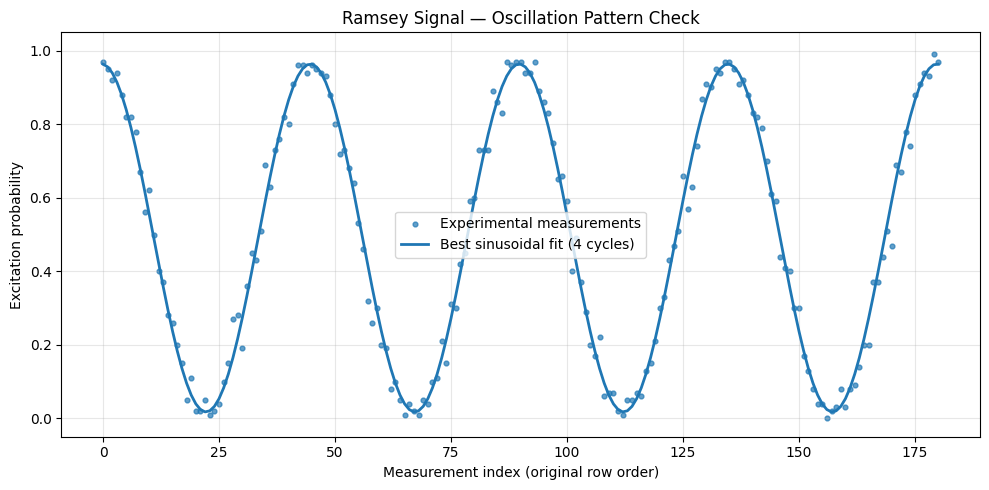

In [15]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

file_path = Path(
    "/content/ramsey_data/Ramsey/0+1/step_2_delay_1_ms.xlsx"
)

data = pd.read_excel(file_path)
probability = data["probability"].to_numpy(dtype=float)

scan_index = np.arange(len(probability))
number_of_points = len(probability)

best_fit = None

for cycles in range(1, 11):
    angle = 2 * np.pi * cycles * scan_index / (number_of_points - 1)

    design_matrix = np.column_stack([
        np.ones(number_of_points),
        np.cos(angle),
        np.sin(angle)
    ])

    coefficients, *_ = np.linalg.lstsq(
        design_matrix,
        probability,
        rcond=None
    )

    fitted_probability = design_matrix @ coefficients
    residual_sum = np.sum((probability - fitted_probability) ** 2)

    if best_fit is None or residual_sum < best_fit["rss"]:
        best_fit = {
            "cycles": cycles,
            "coefficients": coefficients,
            "fitted_probability": fitted_probability,
            "rss": residual_sum
        }

offset, cosine_term, sine_term = best_fit["coefficients"]
amplitude = np.hypot(cosine_term, sine_term)

total_sum = np.sum((probability - probability.mean()) ** 2)
r_squared = 1 - best_fit["rss"] / total_sum

print(f"Measurements: {number_of_points}")
print(f"Best cycle count among tested models: {best_fit['cycles']}")
print(f"Fitted offset: {offset:.4f}")
print(f"Fitted sinusoidal amplitude: {amplitude:.4f}")
print(f"Fit R-squared: {r_squared:.4f}")

plt.figure(figsize=(10, 5))

plt.scatter(
    scan_index,
    probability,
    s=12,
    alpha=0.7,
    label="Experimental measurements"
)

plt.plot(
    scan_index,
    best_fit["fitted_probability"],
    linewidth=2,
    label=f"Best sinusoidal fit ({best_fit['cycles']} cycles)"
)

plt.xlabel("Measurement index (original row order)")
plt.ylabel("Excitation probability")
plt.title("Ramsey Signal — Oscillation Pattern Check")
plt.ylim(-0.05, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


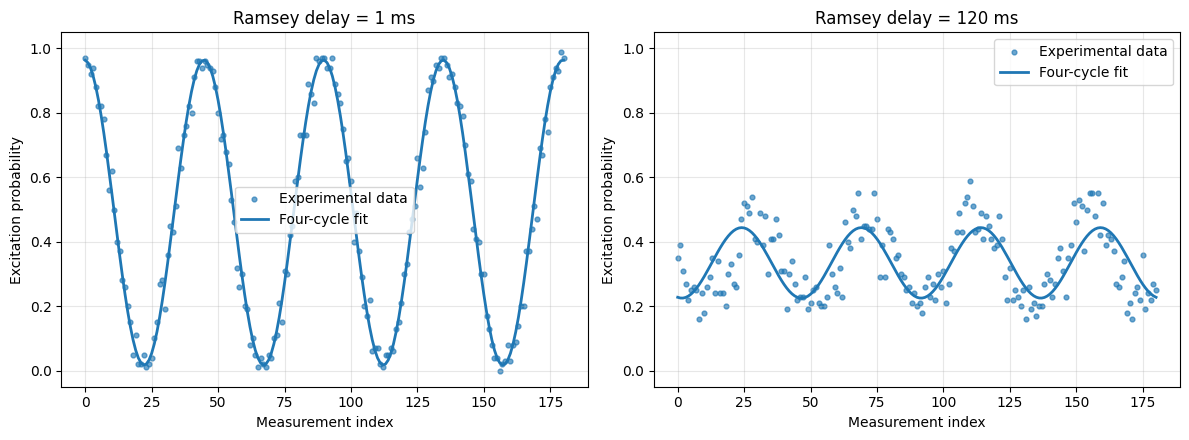

,Delay (ms),Measurements,Fitted offset,Estimated contrast,Contrast SE,R-squared
0,1,181,0.4906,0.9465,0.0079,0.9878
1,120,181,0.3344,0.2188,0.0164,0.5012


In [16]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("/content/ramsey_data/Ramsey/0+1")
DELAYS_MS = [1, 120]
CYCLE_COUNT = 4


def fit_ramsey_fringe(file_path, cycle_count=4):
    data = pd.read_excel(file_path)
    probability = data["probability"].to_numpy(dtype=float)

    scan_position = np.arange(len(probability))
    phase = (
        2 * np.pi * cycle_count
        * scan_position / (len(probability) - 1)
    )

    design_matrix = np.column_stack([
        np.ones(len(probability)),
        np.cos(phase),
        np.sin(phase)
    ])

    coefficients, *_ = np.linalg.lstsq(
        design_matrix,
        probability,
        rcond=None
    )

    fitted_probability = design_matrix @ coefficients
    residuals = probability - fitted_probability

    offset, cosine_term, sine_term = coefficients
    amplitude = np.hypot(cosine_term, sine_term)
    contrast = 2 * amplitude

    residual_sum = np.sum(residuals ** 2)
    total_sum = np.sum((probability - probability.mean()) ** 2)
    r_squared = 1 - residual_sum / total_sum

    degrees_of_freedom = len(probability) - len(coefficients)
    residual_variance = residual_sum / degrees_of_freedom

    coefficient_covariance = residual_variance * np.linalg.inv(
        design_matrix.T @ design_matrix
    )

    if amplitude > 0:
        amplitude_direction = np.array([
            cosine_term,
            sine_term
        ]) / amplitude

        amplitude_variance = (
            amplitude_direction
            @ coefficient_covariance[1:3, 1:3]
            @ amplitude_direction
        )

        contrast_se = 2 * np.sqrt(max(amplitude_variance, 0))
    else:
        contrast_se = np.nan

    return {
        "probability": probability,
        "fitted_probability": fitted_probability,
        "measurements": len(probability),
        "offset": offset,
        "contrast": contrast,
        "contrast_SE": contrast_se,
        "R_squared": r_squared
    }


results = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for axis, delay_ms in zip(axes, DELAYS_MS):
    file_path = DATA_DIR / f"step_2_delay_{delay_ms}_ms.xlsx"
    fit = fit_ramsey_fringe(file_path, CYCLE_COUNT)

    results.append({
        "Delay (ms)": delay_ms,
        "Measurements": fit["measurements"],
        "Fitted offset": fit["offset"],
        "Estimated contrast": fit["contrast"],
        "Contrast SE": fit["contrast_SE"],
        "R-squared": fit["R_squared"]
    })

    scan_position = np.arange(fit["measurements"])

    axis.scatter(
        scan_position,
        fit["probability"],
        s=12,
        alpha=0.65,
        label="Experimental data"
    )

    axis.plot(
        scan_position,
        fit["fitted_probability"],
        linewidth=2,
        label="Four-cycle fit"
    )

    axis.set_title(f"Ramsey delay = {delay_ms} ms")
    axis.set_xlabel("Measurement index")
    axis.set_ylabel("Excitation probability")
    axis.set_ylim(-0.05, 1.05)
    axis.grid(alpha=0.3)
    axis.legend()

plt.tight_layout()
plt.show()

comparison = pd.DataFrame(results)
display(comparison.round(4))



Model: 1 cycle(s)
R-squared: 0.0000
Fitted offset: 0.4932
Estimated contrast: 0.0065

Model: 4 cycle(s)
R-squared: 0.9878
Fitted offset: 0.4906
Estimated contrast: 0.9465


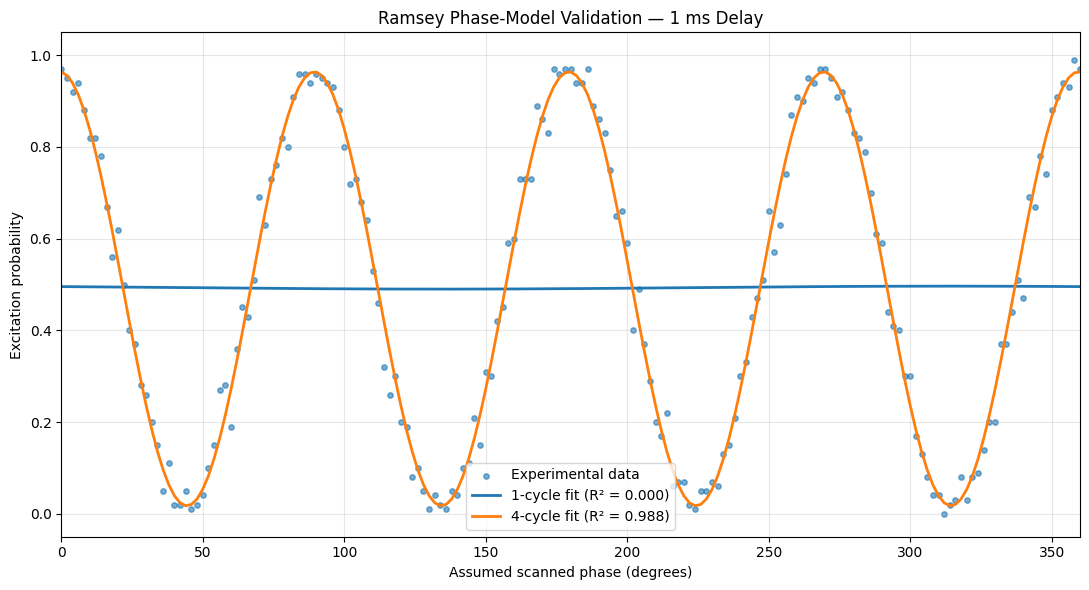

In [17]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

file_path = Path(
    "/content/ramsey_data/Ramsey/0+1/step_2_delay_1_ms.xlsx"
)

data = pd.read_excel(file_path)
probability = data["probability"].to_numpy(dtype=float)

phase_degrees = np.arange(len(probability)) * 2.0

models = {}

for cycle_count in [1, 4]:
    phase_radians = np.deg2rad(
        cycle_count * phase_degrees
    )

    design_matrix = np.column_stack([
        np.ones(len(probability)),
        np.cos(phase_radians),
        np.sin(phase_radians)
    ])

    coefficients, *_ = np.linalg.lstsq(
        design_matrix,
        probability,
        rcond=None
    )

    fitted_probability = design_matrix @ coefficients
    residual_sum = np.sum(
        (probability - fitted_probability) ** 2
    )
    total_sum = np.sum(
        (probability - probability.mean()) ** 2
    )

    amplitude = np.hypot(coefficients[1], coefficients[2])

    models[cycle_count] = {
        "fitted_probability": fitted_probability,
        "r_squared": 1 - residual_sum / total_sum,
        "offset": coefficients[0],
        "amplitude": amplitude,
        "contrast": 2 * amplitude
    }

    print(f"\nModel: {cycle_count} cycle(s)")
    print(f"R-squared: {models[cycle_count]['r_squared']:.4f}")
    print(f"Fitted offset: {coefficients[0]:.4f}")
    print(f"Estimated contrast: {2 * amplitude:.4f}")

plt.figure(figsize=(11, 6))

plt.scatter(
    phase_degrees,
    probability,
    s=15,
    alpha=0.6,
    label="Experimental data"
)

for cycle_count, model in models.items():
    plt.plot(
        phase_degrees,
        model["fitted_probability"],
        linewidth=2,
        label=(
            f"{cycle_count}-cycle fit "
            f"(R² = {model['r_squared']:.3f})"
        )
    )

plt.xlabel("Assumed scanned phase (degrees)")
plt.ylabel("Excitation probability")
plt.title("Ramsey Phase-Model Validation — 1 ms Delay")
plt.xlim(0, 360)
plt.ylim(-0.05, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


,Delay (ms),Measurements,Fitted offset,Contrast,Contrast SE,R-squared
0,0.1,193,0.5041,0.7389,0.0375,0.6714
1,0.2,182,0.4956,0.9250,0.0083,0.9858
2,0.5,183,0.5005,0.9271,0.0098,0.9802
5,1.0,181,0.4906,0.9465,0.0079,0.9878
7,2.0,183,0.4907,0.9326,0.0094,0.9820
9,5.0,181,0.4829,0.8767,0.0090,0.9818
3,10.0,180,0.4768,0.8185,0.0111,0.9684
6,20.0,182,0.4502,0.7145,0.0103,0.9641
8,40.0,182,0.4268,0.5561,0.0133,0.9068
10,80.0,169,0.3889,0.2914,0.0208,0.5418


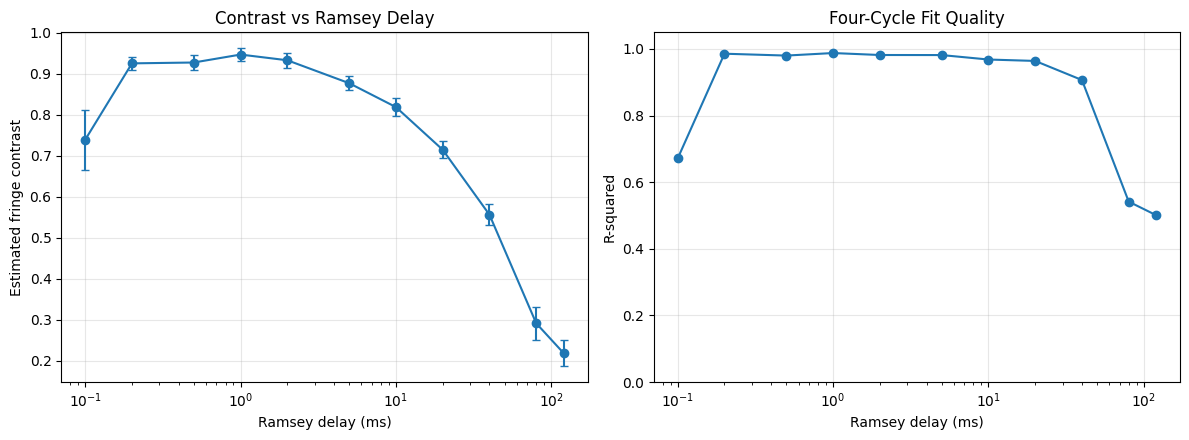

In [18]:

from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("/content/ramsey_data/Ramsey/0+1")
CYCLE_COUNT = 4

filename_pattern = re.compile(
    r"step_2_delay_(?P<delay>[\d.]+)_ms\.xlsx$"
)

results = []

for file_path in sorted(DATA_DIR.glob("step_2_delay_*_ms.xlsx")):
    match = filename_pattern.fullmatch(file_path.name)

    if match is None:
        continue

    data = pd.read_excel(file_path)
    probability = data["probability"].to_numpy(dtype=float)

    point_count = len(probability)
    scan_position = np.linspace(0, 1, point_count)

    angle = 2 * np.pi * CYCLE_COUNT * scan_position

    design_matrix = np.column_stack([
        np.ones(point_count),
        np.cos(angle),
        np.sin(angle)
    ])

    coefficients, *_ = np.linalg.lstsq(
        design_matrix,
        probability,
        rcond=None
    )

    fitted_probability = design_matrix @ coefficients
    residuals = probability - fitted_probability

    residual_sum = np.sum(residuals ** 2)
    total_sum = np.sum((probability - probability.mean()) ** 2)

    offset, cosine_term, sine_term = coefficients
    amplitude = np.hypot(cosine_term, sine_term)
    contrast = 2 * amplitude

    r_squared = (
        1 - residual_sum / total_sum
        if total_sum > 0 else np.nan
    )

    degrees_of_freedom = point_count - design_matrix.shape[1]
    residual_variance = residual_sum / degrees_of_freedom

    coefficient_covariance = residual_variance * np.linalg.inv(
        design_matrix.T @ design_matrix
    )

    if amplitude > 0:
        amplitude_gradient = np.array([
            cosine_term / amplitude,
            sine_term / amplitude
        ])

        amplitude_variance = (
            amplitude_gradient
            @ coefficient_covariance[1:3, 1:3]
            @ amplitude_gradient
        )

        contrast_se = 2 * np.sqrt(max(amplitude_variance, 0))
    else:
        contrast_se = np.nan

    results.append({
        "Delay (ms)": float(match["delay"]),
        "Measurements": point_count,
        "Fitted offset": offset,
        "Contrast": contrast,
        "Contrast SE": contrast_se,
        "R-squared": r_squared
    })

summary = pd.DataFrame(results).sort_values("Delay (ms)")

if summary.empty:
    raise ValueError("No matching step_2 Ramsey files were found.")

display(summary.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].errorbar(
    summary["Delay (ms)"],
    summary["Contrast"],
    yerr=1.96 * summary["Contrast SE"],
    fmt="o-",
    capsize=3
)
axes[0].set_xscale("log")
axes[0].set_xlabel("Ramsey delay (ms)")
axes[0].set_ylabel("Estimated fringe contrast")
axes[0].set_title("Contrast vs Ramsey Delay")
axes[0].grid(alpha=0.3)

axes[1].plot(
    summary["Delay (ms)"],
    summary["R-squared"],
    "o-"
)
axes[1].set_xscale("log")
axes[1].set_xlabel("Ramsey delay (ms)")
axes[1].set_ylabel("R-squared")
axes[1].set_title("Four-Cycle Fit Quality")
axes[1].set_ylim(0, 1.05)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


,Delay (ms),Measurements,Best cycle count,Best-fit R-squared,Four-cycle R-squared,Exploratory contrast
8,0.1,193,4,0.6714,0.6714,0.7389
10,0.2,182,4,0.9858,0.9858,0.9250
1,0.5,183,4,0.9802,0.9802,0.9271
0,1.0,181,4,0.9878,0.9878,0.9465
9,2.0,183,4,0.9820,0.9820,0.9326
2,5.0,181,4,0.9818,0.9818,0.8767
3,10.0,180,4,0.9684,0.9684,0.8185
6,20.0,182,4,0.9641,0.9641,0.7145
7,40.0,182,4,0.9068,0.9068,0.5561
4,80.0,169,4,0.5418,0.5418,0.2914


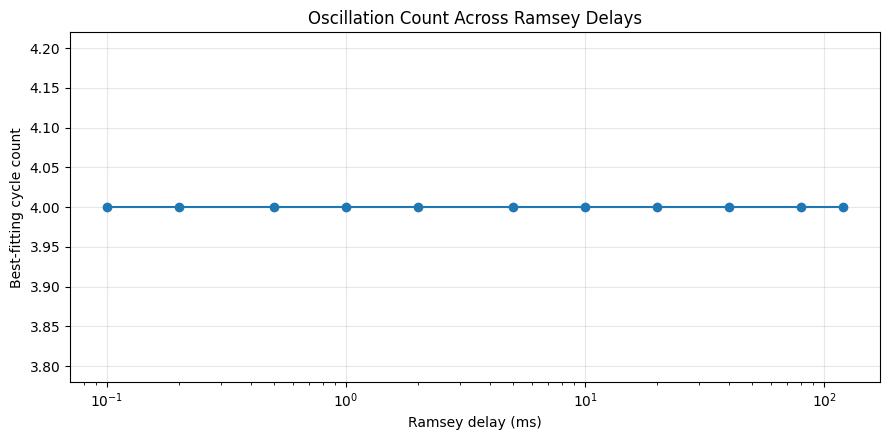

In [19]:

from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("/content/ramsey_data/Ramsey/0+1")

filename_pattern = re.compile(
    r"step_2_delay_(?P<delay>[\d.]+)_ms\.xlsx$"
)

results = []

for file_path in DATA_DIR.glob("step_2_delay_*_ms.xlsx"):
    match = filename_pattern.fullmatch(file_path.name)

    if match is None:
        continue

    data = pd.read_excel(file_path)
    probability = data["probability"].to_numpy(dtype=float)
    point_count = len(probability)

    if point_count < 10:
        continue

    # Use the original row order, without assigning physical phase values.
    scan_position = np.linspace(0, 1, point_count)
    total_variation = np.sum(
        (probability - probability.mean()) ** 2
    )

    best_model = None
    four_cycle_r_squared = np.nan

    for cycle_count in range(1, 11):
        angle = 2 * np.pi * cycle_count * scan_position

        design_matrix = np.column_stack([
            np.ones(point_count),
            np.cos(angle),
            np.sin(angle)
        ])

        coefficients, *_ = np.linalg.lstsq(
            design_matrix,
            probability,
            rcond=None
        )

        fitted_probability = design_matrix @ coefficients
        residual_sum = np.sum(
            (probability - fitted_probability) ** 2
        )

        r_squared = (
            1 - residual_sum / total_variation
            if total_variation > 0 else np.nan
        )

        if cycle_count == 4:
            four_cycle_r_squared = r_squared

        if best_model is None or residual_sum < best_model["rss"]:
            amplitude = np.hypot(
                coefficients[1],
                coefficients[2]
            )

            best_model = {
                "cycles": cycle_count,
                "rss": residual_sum,
                "r_squared": r_squared,
                "contrast": 2 * amplitude
            }

    results.append({
        "Delay (ms)": float(match["delay"]),
        "Measurements": point_count,
        "Best cycle count": best_model["cycles"],
        "Best-fit R-squared": best_model["r_squared"],
        "Four-cycle R-squared": four_cycle_r_squared,
        "Exploratory contrast": best_model["contrast"]
    })

summary = pd.DataFrame(results).sort_values("Delay (ms)")
display(summary.round(4))

plt.figure(figsize=(9, 4.5))
plt.plot(
    summary["Delay (ms)"],
    summary["Best cycle count"],
    "o-"
)
plt.xscale("log")
plt.xlabel("Ramsey delay (ms)")
plt.ylabel("Best-fitting cycle count")
plt.title("Oscillation Count Across Ramsey Delays")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



,Delay (ms),Contrast,Contrast SE,Fringe R-squared,Exponential fit,Gaussian fit
0,0.1,0.7389,0.0375,0.6714,0.9386,0.9016
1,0.2,0.9250,0.0083,0.9858,0.9374,0.9016
2,0.5,0.9271,0.0098,0.9802,0.9336,0.9016
5,1.0,0.9465,0.0079,0.9878,0.9275,0.9014
7,2.0,0.9326,0.0094,0.9820,0.9152,0.9007
9,5.0,0.8767,0.0090,0.9818,0.8795,0.8957
3,10.0,0.8185,0.0111,0.9684,0.8231,0.8780
6,20.0,0.7145,0.0103,0.9641,0.7208,0.8109
8,40.0,0.5561,0.0133,0.9068,0.5528,0.5899
10,80.0,0.2914,0.0208,0.5418,0.3251,0.1652


,Model,Initial contrast,Decay time (ms),Weighted chi-squared,AICc
0,Exponential,0.9398,75.3639,46.4382,51.9382
1,Gaussian,0.9016,61.4085,389.9749,395.4749


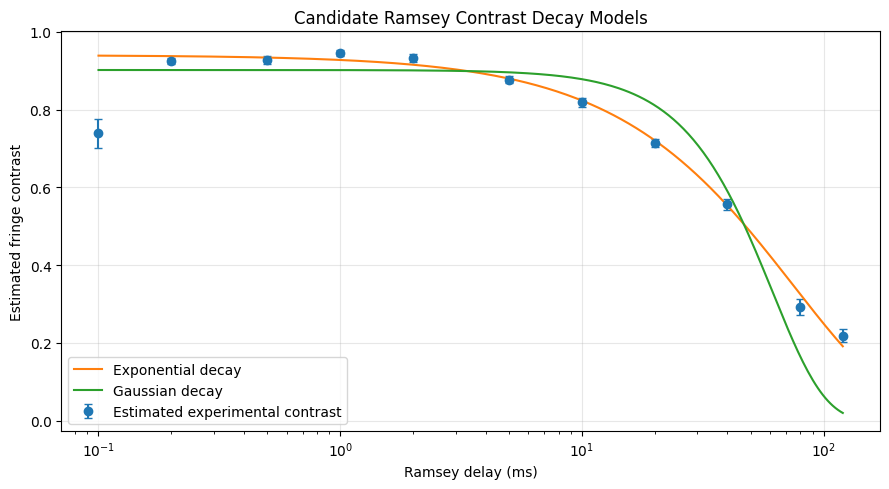

In [20]:

from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

DATA_DIR = Path("/content/ramsey_data/Ramsey/0+1")
CYCLE_COUNT = 4

filename_pattern = re.compile(
    r"step_2_delay_(?P<delay>[\d.]+)_ms\.xlsx$"
)


def estimate_contrast(file_path):
    data = pd.read_excel(file_path)
    probability = data["probability"].to_numpy(dtype=float)

    point_count = len(probability)
    position = np.linspace(0, 1, point_count)
    angle = 2 * np.pi * CYCLE_COUNT * position

    design_matrix = np.column_stack([
        np.ones(point_count),
        np.cos(angle),
        np.sin(angle)
    ])

    coefficients, *_ = np.linalg.lstsq(
        design_matrix, probability, rcond=None
    )

    fitted = design_matrix @ coefficients
    residuals = probability - fitted

    residual_variance = (
        np.sum(residuals ** 2)
        / (point_count - design_matrix.shape[1])
    )

    covariance = residual_variance * np.linalg.inv(
        design_matrix.T @ design_matrix
    )

    cosine_term, sine_term = coefficients[1:3]
    amplitude = np.hypot(cosine_term, sine_term)
    contrast = 2 * amplitude

    if amplitude == 0:
        contrast_se = np.nan
    else:
        gradient = np.array([cosine_term, sine_term]) / amplitude
        amplitude_variance = (
            gradient @ covariance[1:3, 1:3] @ gradient
        )
        contrast_se = 2 * np.sqrt(max(amplitude_variance, 0))

    total_variance = np.sum(
        (probability - probability.mean()) ** 2
    )
    r_squared = 1 - np.sum(residuals ** 2) / total_variance

    return contrast, contrast_se, r_squared


records = []

for file_path in sorted(DATA_DIR.glob("step_2_delay_*_ms.xlsx")):
    match = filename_pattern.fullmatch(file_path.name)

    if match is None:
        continue

    contrast, contrast_se, r_squared = estimate_contrast(file_path)

    records.append({
        "Delay (ms)": float(match["delay"]),
        "Contrast": contrast,
        "Contrast SE": contrast_se,
        "Fringe R-squared": r_squared
    })

results = pd.DataFrame(records).sort_values("Delay (ms)")
results = results.dropna(
    subset=["Delay (ms)", "Contrast", "Contrast SE"]
)

delay = results["Delay (ms)"].to_numpy()
contrast = results["Contrast"].to_numpy()
uncertainty = results["Contrast SE"].to_numpy()


def exponential_decay(time, initial_contrast, decay_time):
    return initial_contrast * np.exp(-time / decay_time)


def gaussian_decay(time, initial_contrast, decay_time):
    return initial_contrast * np.exp(-(time / decay_time) ** 2)


models = {
    "Exponential": exponential_decay,
    "Gaussian": gaussian_decay
}

fit_results = []

for model_name, model_function in models.items():
    parameters, covariance = curve_fit(
        model_function,
        delay,
        contrast,
        p0=[0.95, 50],
        sigma=uncertainty,
        absolute_sigma=True,
        bounds=([0, 0.001], [1.0, 10000]),
        maxfev=20000
    )

    predicted = model_function(delay, *parameters)
    chi_squared = np.sum(
        ((contrast - predicted) / uncertainty) ** 2
    )

    parameter_count = len(parameters)
    sample_count = len(delay)

    aicc = (
        chi_squared
        + 2 * parameter_count
        + (
            2 * parameter_count * (parameter_count + 1)
            / (sample_count - parameter_count - 1)
        )
    )

    fit_results.append({
        "Model": model_name,
        "Initial contrast": parameters[0],
        "Decay time (ms)": parameters[1],
        "Weighted chi-squared": chi_squared,
        "AICc": aicc
    })

    results[f"{model_name} fit"] = predicted

model_comparison = pd.DataFrame(fit_results).sort_values("AICc")
display(results.round(4))
display(model_comparison.round(4))

time_grid = np.logspace(
    np.log10(delay.min()),
    np.log10(delay.max()),
    300
)

plt.figure(figsize=(9, 5))

plt.errorbar(
    delay,
    contrast,
    yerr=uncertainty,
    fmt="o",
    capsize=3,
    label="Estimated experimental contrast"
)

for row in fit_results:
    model_name = row["Model"]
    model_function = models[model_name]

    parameters = [
        row["Initial contrast"],
        row["Decay time (ms)"]
    ]

    plt.plot(
        time_grid,
        model_function(time_grid, *parameters),
        label=f"{model_name} decay"
    )

plt.xscale("log")
plt.xlabel("Ramsey delay (ms)")
plt.ylabel("Estimated fringe contrast")
plt.title("Candidate Ramsey Contrast Decay Models")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


,Delay (ms),Measurements,Fitted offset,Binomial contrast,R-squared,Negative log-likelihood
0,0.1,193,0.5123,0.7337,0.6707,10518.6846
1,0.2,182,0.4935,0.9224,0.9858,8113.2853
2,0.5,183,0.4962,0.9260,0.9801,8093.6081
5,1.0,181,0.4921,0.9452,0.9878,7738.1722
7,2.0,183,0.4923,0.9332,0.9819,8030.9151
9,5.0,181,0.4832,0.8661,0.9816,8592.6055
3,10.0,180,0.4772,0.8172,0.9683,9092.5096
6,20.0,182,0.4517,0.7151,0.9641,9976.0991
8,40.0,182,0.4257,0.5587,0.9068,10910.2983
10,80.0,169,0.3891,0.2894,0.5417,10912.4029


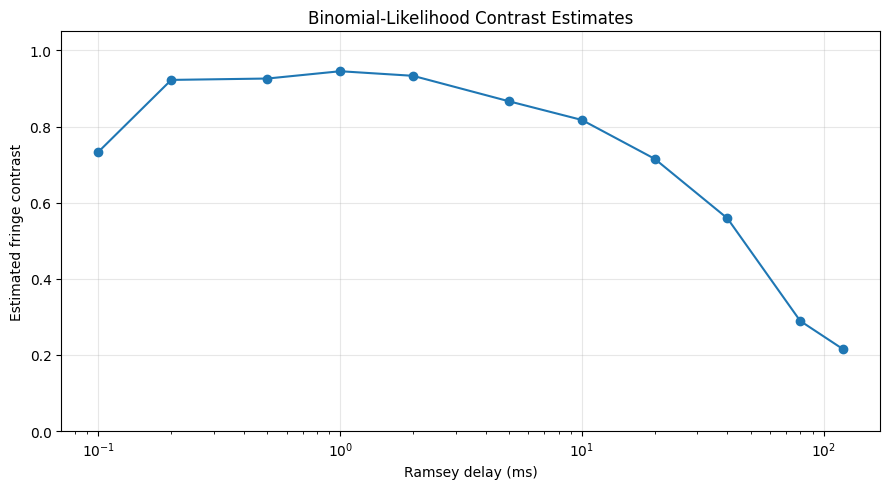

In [21]:

from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

DATA_DIR = Path("/content/ramsey_data/Ramsey/0+1")
SHOTS_PER_POINT = 100
CYCLE_COUNT = 4

filename_pattern = re.compile(
    r"step_2_delay_(?P<delay>[\d.]+)_ms\.xlsx$"
)


def fit_fringe(probability):
    point_count = len(probability)
    successes = np.rint(
        probability * SHOTS_PER_POINT
    ).astype(int)

    scan_position = np.linspace(0, 1, point_count)
    phase = 2 * np.pi * CYCLE_COUNT * scan_position

    def negative_log_likelihood(parameters):
        offset, amplitude_fraction, phase_offset = parameters

        amplitude = amplitude_fraction * min(offset, 1 - offset)

        predicted = offset + amplitude * np.cos(
            phase + phase_offset
        )
        predicted = np.clip(predicted, 1e-9, 1 - 1e-9)

        log_likelihood = (
            successes * np.log(predicted)
            + (SHOTS_PER_POINT - successes)
            * np.log1p(-predicted)
        )

        return -np.sum(log_likelihood)

    best_fit = None

    for initial_phase in np.linspace(-np.pi, np.pi, 13):
        fit = minimize(
            negative_log_likelihood,
            x0=[float(probability.mean()), 0.9, initial_phase],
            method="L-BFGS-B",
            bounds=[
                (1e-4, 1 - 1e-4),
                (0, 1),
                (-np.pi, np.pi)
            ]
        )

        if fit.success and (
            best_fit is None or fit.fun < best_fit.fun
        ):
            best_fit = fit

    if best_fit is None:
        raise RuntimeError("The fringe fit did not converge.")

    offset, amplitude_fraction, phase_offset = best_fit.x
    amplitude = amplitude_fraction * min(offset, 1 - offset)

    predicted = offset + amplitude * np.cos(
        phase + phase_offset
    )

    residual_sum = np.sum((probability - predicted) ** 2)
    total_sum = np.sum((probability - probability.mean()) ** 2)

    r_squared = (
        1 - residual_sum / total_sum
        if total_sum > 0 else np.nan
    )

    return {
        "offset": offset,
        "contrast": 2 * amplitude,
        "R_squared": r_squared,
        "negative_log_likelihood": best_fit.fun
    }


records = []

for file_path in sorted(DATA_DIR.glob("step_2_delay_*_ms.xlsx")):
    match = filename_pattern.fullmatch(file_path.name)

    if match is None:
        continue

    data = pd.read_excel(file_path)
    probability = data["probability"].to_numpy(dtype=float)

    if np.any((probability < 0) | (probability > 1)):
        raise ValueError(f"Invalid probability in {file_path.name}")

    fit = fit_fringe(probability)

    records.append({
        "Delay (ms)": float(match["delay"]),
        "Measurements": len(probability),
        "Fitted offset": fit["offset"],
        "Binomial contrast": fit["contrast"],
        "R-squared": fit["R_squared"],
        "Negative log-likelihood": fit["negative_log_likelihood"]
    })

contrast_results = pd.DataFrame(records).sort_values("Delay (ms)")
display(contrast_results.round(4))

plt.figure(figsize=(9, 5))

plt.plot(
    contrast_results["Delay (ms)"],
    contrast_results["Binomial contrast"],
    "o-"
)

plt.xscale("log")
plt.xlabel("Ramsey delay (ms)")
plt.ylabel("Estimated fringe contrast")
plt.title("Binomial-Likelihood Contrast Estimates")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


,Delay (ms),Contrast,95% CI lower,95% CI upper,Fringe R-squared
0,0.1,0.7337,0.7178,0.7478,0.6707
1,0.2,0.9224,0.9119,0.9322,0.9858
2,0.5,0.9260,0.9167,0.9368,0.9801
5,1.0,0.9452,0.9367,0.9542,0.9878
7,2.0,0.9332,0.9231,0.9424,0.9819
9,5.0,0.8661,0.8539,0.8767,0.9816
3,10.0,0.8172,0.8020,0.8301,0.9683
6,20.0,0.7151,0.6970,0.7309,0.9641
8,40.0,0.5587,0.5441,0.5765,0.9068
10,80.0,0.2894,0.2693,0.3084,0.5417


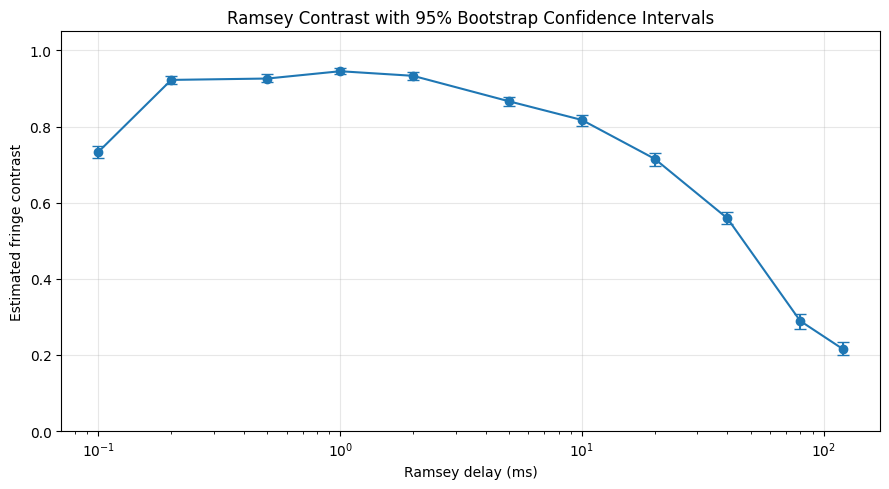

In [22]:

from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

DATA_DIR = Path("/content/ramsey_data/Ramsey/0+1")
SHOTS_PER_POINT = 100
CYCLE_COUNT = 4
BOOTSTRAP_SAMPLES = 200
RANDOM_SEED = 42

filename_pattern = re.compile(
    r"step_2_delay_(?P<delay>[\d.]+)_ms\.xlsx$"
)


def fit_fringe(probability, initial_parameters=None):
    point_count = len(probability)
    successes = np.rint(
        probability * SHOTS_PER_POINT
    ).astype(int)

    scan_position = np.linspace(0, 1, point_count)
    phase = 2 * np.pi * CYCLE_COUNT * scan_position

    # Estimate a sensible starting point using linear least squares.
    design_matrix = np.column_stack([
        np.ones(point_count),
        np.cos(phase),
        np.sin(phase)
    ])

    linear_coefficients, *_ = np.linalg.lstsq(
        design_matrix,
        probability,
        rcond=None
    )

    offset_start = np.clip(linear_coefficients[0], 0.01, 0.99)
    amplitude_start = np.hypot(
        linear_coefficients[1],
        linear_coefficients[2]
    )

    maximum_amplitude = min(offset_start, 1 - offset_start)
    fraction_start = np.clip(
        amplitude_start / max(maximum_amplitude, 1e-8),
        0.01,
        0.99
    )

    phase_start = np.arctan2(
        -linear_coefficients[2],
        linear_coefficients[1]
    )

    starts = [
        [offset_start, fraction_start, phase_start],
        [offset_start, fraction_start, phase_start + np.pi / 2],
        [offset_start, fraction_start, phase_start - np.pi / 2],
        [offset_start, fraction_start, phase_start + np.pi]
    ]

    if initial_parameters is not None:
        starts.insert(0, initial_parameters)

    def negative_log_likelihood(parameters):
        offset, amplitude_fraction, phase_offset = parameters

        amplitude = (
            amplitude_fraction
            * min(offset, 1 - offset)
        )

        predicted = offset + amplitude * np.cos(
            phase + phase_offset
        )

        predicted = np.clip(predicted, 1e-9, 1 - 1e-9)

        return -np.sum(
            successes * np.log(predicted)
            + (SHOTS_PER_POINT - successes)
            * np.log1p(-predicted)
        )

    best_fit = None

    for start in starts:
        fit = minimize(
            negative_log_likelihood,
            x0=start,
            method="L-BFGS-B",
            bounds=[
                (0.001, 0.999),
                (0, 1),
                (-np.pi, np.pi)
            ]
        )

        if fit.success and (
            best_fit is None or fit.fun < best_fit.fun
        ):
            best_fit = fit

    if best_fit is None:
        raise RuntimeError("The fringe fit did not converge.")

    offset, amplitude_fraction, phase_offset = best_fit.x

    amplitude = amplitude_fraction * min(offset, 1 - offset)
    contrast = 2 * amplitude

    fitted_probability = offset + amplitude * np.cos(
        phase + phase_offset
    )

    total_sum = np.sum(
        (probability - probability.mean()) ** 2
    )
    residual_sum = np.sum(
        (probability - fitted_probability) ** 2
    )

    r_squared = (
        1 - residual_sum / total_sum
        if total_sum > 0 else np.nan
    )

    return {
        "offset": offset,
        "contrast": contrast,
        "phase_offset": phase_offset,
        "fitted_probability": fitted_probability,
        "r_squared": r_squared
    }


rng = np.random.default_rng(RANDOM_SEED)
results = []

for file_path in sorted(DATA_DIR.glob("step_2_delay_*_ms.xlsx")):
    match = filename_pattern.fullmatch(file_path.name)

    if match is None:
        continue

    data = pd.read_excel(file_path)
    probability = data["probability"].to_numpy(dtype=float)

    fitted = fit_fringe(probability)
    simulated_probability = fitted["fitted_probability"]

    bootstrap_contrasts = []

    for _ in range(BOOTSTRAP_SAMPLES):
        simulated_counts = rng.binomial(
            SHOTS_PER_POINT,
            np.clip(simulated_probability, 0, 1)
        )

        simulated_data = simulated_counts / SHOTS_PER_POINT

        bootstrap_fit = fit_fringe(
            simulated_data,
            initial_parameters=[
                fitted["offset"],
                min(
                    fitted["contrast"]
                    / (2 * min(
                        fitted["offset"],
                        1 - fitted["offset"]
                    )),
                    1
                ),
                fitted["phase_offset"]
            ]
        )

        bootstrap_contrasts.append(bootstrap_fit["contrast"])

    lower, upper = np.percentile(
        bootstrap_contrasts,
        [2.5, 97.5]
    )

    results.append({
        "Delay (ms)": float(match["delay"]),
        "Contrast": fitted["contrast"],
        "95% CI lower": lower,
        "95% CI upper": upper,
        "Fringe R-squared": fitted["r_squared"]
    })

contrast_summary = pd.DataFrame(results).sort_values("Delay (ms)")
display(contrast_summary.round(4))

plt.figure(figsize=(9, 5))

plt.errorbar(
    contrast_summary["Delay (ms)"],
    contrast_summary["Contrast"],
    yerr=[
        contrast_summary["Contrast"] - contrast_summary["95% CI lower"],
        contrast_summary["95% CI upper"] - contrast_summary["Contrast"]
    ],
    fmt="o-",
    capsize=4
)

plt.xscale("log")
plt.xlabel("Ramsey delay (ms)")
plt.ylabel("Estimated fringe contrast")
plt.title("Ramsey Contrast with 95% Bootstrap Confidence Intervals")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


,Data subset,Model,Points,Initial contrast,Decay time (ms),Approx. decay-time SE (ms),Reduced chi-squared,AICc
0,All measurements,Exponential,11,0.9241,78.0936,1.2655,81.7923,741.6303
1,All measurements,Gaussian,11,0.8924,72.9069,0.8250,161.8890,1462.5013
2,Fringe R-squared >= 0.90,Exponential,8,0.9414,74.8480,1.8226,7.6917,52.5502
3,Fringe R-squared >= 0.90,Gaussian,8,0.9150,53.2039,0.7209,51.5682,315.8089


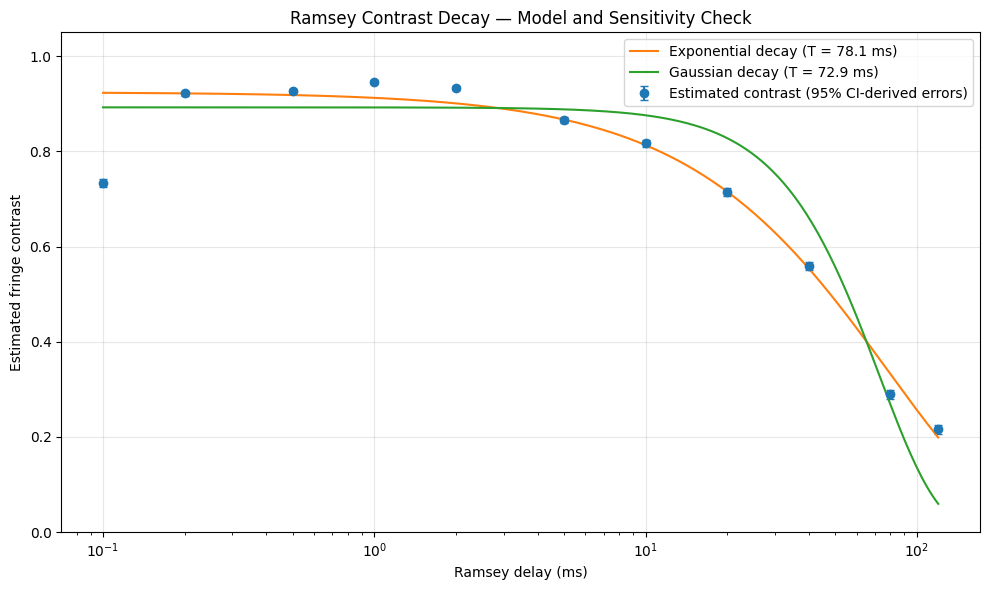

In [23]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

data = contrast_summary.copy().sort_values("Delay (ms)")

delay = data["Delay (ms)"].to_numpy(dtype=float)
contrast = data["Contrast"].to_numpy(dtype=float)

contrast_se = (
    data["95% CI upper"].to_numpy(dtype=float)
    - data["95% CI lower"].to_numpy(dtype=float)
) / (2 * 1.96)

fit_quality = data["Fringe R-squared"].to_numpy(dtype=float)


def exponential_decay(time, initial_contrast, decay_time):
    return initial_contrast * np.exp(-time / decay_time)


def gaussian_decay(time, initial_contrast, decay_time):
    return initial_contrast * np.exp(-(time / decay_time) ** 2)


models = {
    "Exponential": exponential_decay,
    "Gaussian": gaussian_decay
}

analysis_groups = {
    "All measurements": np.ones(len(data), dtype=bool),
    "Fringe R-squared >= 0.90": fit_quality >= 0.90
}

fit_records = []

for group_name, mask in analysis_groups.items():
    group_delay = delay[mask]
    group_contrast = contrast[mask]
    group_se = contrast_se[mask]

    for model_name, model_function in models.items():
        parameters, covariance = curve_fit(
            model_function,
            group_delay,
            group_contrast,
            p0=[0.95, 50],
            sigma=group_se,
            absolute_sigma=True,
            bounds=([0.0, 0.001], [1.0, 10000]),
            maxfev=20000
        )

        initial_contrast, decay_time = parameters
        parameter_se = np.sqrt(np.diag(covariance))

        predicted = model_function(group_delay, *parameters)
        chi_squared = np.sum(
            ((group_contrast - predicted) / group_se) ** 2
        )

        point_count = len(group_delay)
        parameter_count = len(parameters)

        reduced_chi_squared = (
            chi_squared / (point_count - parameter_count)
        )

        aicc = (
            chi_squared
            + 2 * parameter_count
            + (
                2 * parameter_count * (parameter_count + 1)
                / (point_count - parameter_count - 1)
            )
        )

        fit_records.append({
            "Data subset": group_name,
            "Model": model_name,
            "Points": point_count,
            "Initial contrast": initial_contrast,
            "Decay time (ms)": decay_time,
            "Approx. decay-time SE (ms)": parameter_se[1],
            "Reduced chi-squared": reduced_chi_squared,
            "AICc": aicc
        })

fit_summary = pd.DataFrame(fit_records)

display(
    fit_summary.sort_values(
        ["Data subset", "AICc"]
    ).round(4)
)

time_grid = np.logspace(
    np.log10(delay.min()),
    np.log10(delay.max()),
    300
)

plt.figure(figsize=(10, 6))

plt.errorbar(
    delay,
    contrast,
    yerr=contrast_se,
    fmt="o",
    capsize=3,
    label="Estimated contrast (95% CI-derived errors)"
)

full_data_results = fit_summary[
    fit_summary["Data subset"] == "All measurements"
]

for _, result in full_data_results.iterrows():
    model_function = models[result["Model"]]

    fitted_curve = model_function(
        time_grid,
        result["Initial contrast"],
        result["Decay time (ms)"]
    )

    plt.plot(
        time_grid,
        fitted_curve,
        label=(
            f"{result['Model']} decay "
            f"(T = {result['Decay time (ms)']:.1f} ms)"
        )
    )

plt.xscale("log")
plt.xlabel("Ramsey delay (ms)")
plt.ylabel("Estimated fringe contrast")
plt.title("Ramsey Contrast Decay — Model and Sensitivity Check")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


,Delay (ms),Observed contrast,Predicted contrast,Residual,Standardized residual,Chi-squared contribution
0,0.1,0.7337,0.9230,-0.1893,-24.7733,613.7172
3,1.0,0.9452,0.9124,0.0328,7.3725,54.3543
4,2.0,0.9332,0.9008,0.0324,6.5647,43.0949
9,80.0,0.2894,0.3318,-0.0424,-4.2518,18.0777
10,120.0,0.2157,0.1988,0.0169,1.9601,3.8419
2,0.5,0.9260,0.9182,0.0078,1.5233,2.3204
8,40.0,0.5587,0.5537,0.0050,0.6044,0.3653
6,10.0,0.8172,0.8131,0.0041,0.5732,0.3286
1,0.2,0.9224,0.9218,0.0006,0.1258,0.0158
5,5.0,0.8661,0.8668,-0.0007,-0.1166,0.0136


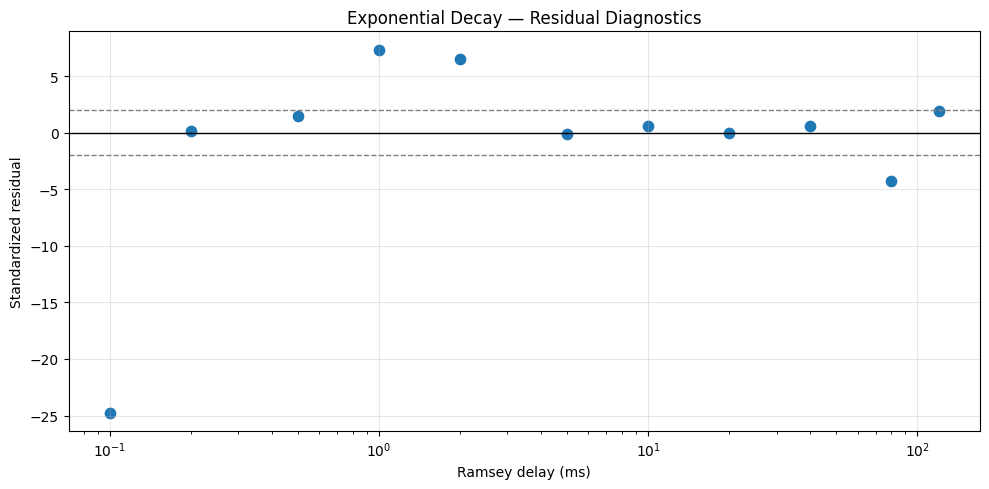

In [24]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data = contrast_summary.copy().sort_values("Delay (ms)")

delay = data["Delay (ms)"].to_numpy(dtype=float)
observed = data["Contrast"].to_numpy(dtype=float)

standard_error = (
    data["95% CI upper"].to_numpy(dtype=float)
    - data["95% CI lower"].to_numpy(dtype=float)
) / (2 * 1.96)

exponential_fit = fit_summary[
    (fit_summary["Data subset"] == "All measurements")
    & (fit_summary["Model"] == "Exponential")
].iloc[0]

initial_contrast = exponential_fit["Initial contrast"]
decay_time = exponential_fit["Decay time (ms)"]

predicted = initial_contrast * np.exp(-delay / decay_time)

residual = observed - predicted
standardized_residual = residual / standard_error

diagnostics = pd.DataFrame({
    "Delay (ms)": delay,
    "Observed contrast": observed,
    "Predicted contrast": predicted,
    "Residual": residual,
    "Standardized residual": standardized_residual,
    "Chi-squared contribution": standardized_residual ** 2
})

diagnostics = diagnostics.sort_values(
    "Chi-squared contribution",
    ascending=False
)

display(diagnostics.round(4))

diagnostics = diagnostics.sort_values("Delay (ms)")

plt.figure(figsize=(10, 5))

plt.axhline(0, color="black", linewidth=1)
plt.axhline(2, color="gray", linestyle="--", linewidth=1)
plt.axhline(-2, color="gray", linestyle="--", linewidth=1)

plt.scatter(
    diagnostics["Delay (ms)"],
    diagnostics["Standardized residual"],
    s=55
)

plt.xscale("log")
plt.xlabel("Ramsey delay (ms)")
plt.ylabel("Standardized residual")
plt.title("Exponential Decay — Residual Diagnostics")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


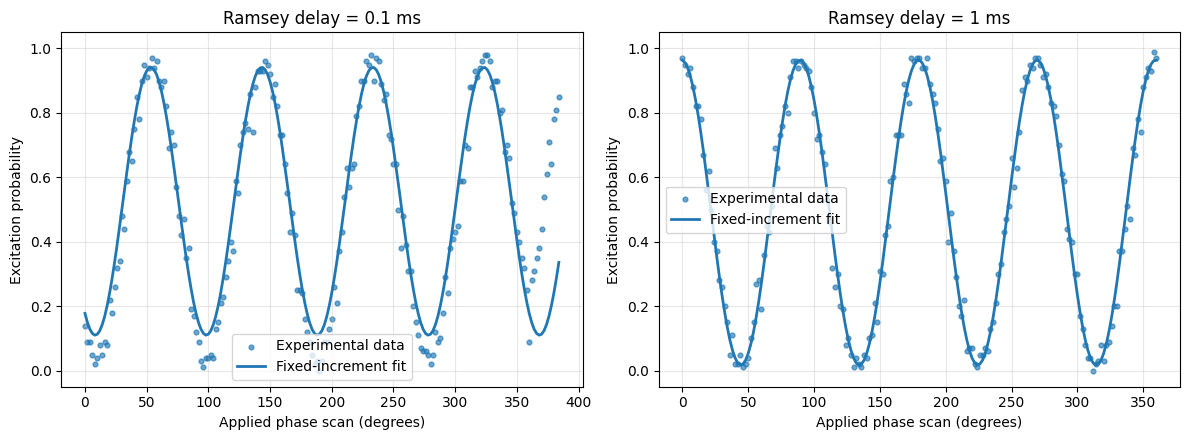

,Delay (ms),Measurements,Last phase value (degrees),Estimated contrast,R-squared
0,0.1,193,384.0,0.8315,0.8672
1,1.0,181,360.0,0.9465,0.9878


In [25]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("/content/ramsey_data/Ramsey/0+1")

PHASE_STEP_DEGREES = 2.0
EMPIRICAL_CYCLE_COUNT = 4
DELAYS_MS = [0.1, 1.0]

results = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for axis, delay_ms in zip(axes, DELAYS_MS):
    file_path = DATA_DIR / f"step_2_delay_{delay_ms:g}_ms.xlsx"

    data = pd.read_excel(file_path)
    probability = data["probability"].to_numpy(dtype=float)

    phase_degrees = (
        np.arange(len(probability)) * PHASE_STEP_DEGREES
    )

    effective_phase = np.deg2rad(
        EMPIRICAL_CYCLE_COUNT * phase_degrees
    )

    design_matrix = np.column_stack([
        np.ones(len(probability)),
        np.cos(effective_phase),
        np.sin(effective_phase)
    ])

    coefficients, *_ = np.linalg.lstsq(
        design_matrix,
        probability,
        rcond=None
    )

    fitted_probability = design_matrix @ coefficients
    residuals = probability - fitted_probability

    residual_sum = np.sum(residuals ** 2)
    total_sum = np.sum(
        (probability - probability.mean()) ** 2
    )

    r_squared = (
        1 - residual_sum / total_sum
        if total_sum > 0 else np.nan
    )

    contrast = 2 * np.hypot(
        coefficients[1],
        coefficients[2]
    )

    results.append({
        "Delay (ms)": delay_ms,
        "Measurements": len(probability),
        "Last phase value (degrees)": phase_degrees[-1],
        "Estimated contrast": contrast,
        "R-squared": r_squared
    })

    axis.scatter(
        phase_degrees,
        probability,
        s=12,
        alpha=0.65,
        label="Experimental data"
    )

    axis.plot(
        phase_degrees,
        fitted_probability,
        linewidth=2,
        label="Fixed-increment fit"
    )

    axis.set_title(f"Ramsey delay = {delay_ms:g} ms")
    axis.set_xlabel("Applied phase scan (degrees)")
    axis.set_ylabel("Excitation probability")
    axis.set_ylim(-0.05, 1.05)
    axis.grid(alpha=0.3)
    axis.legend()

plt.tight_layout()
plt.show()

display(pd.DataFrame(results).round(4))


,Points used,Additional points beyond 180,Estimated contrast,Fit R-squared,R-squared on common first 180
0,180,0,0.9123,0.9833,0.9833
1,181,1,0.9130,0.9833,0.9833
2,193,13,0.8315,0.8672,0.9674


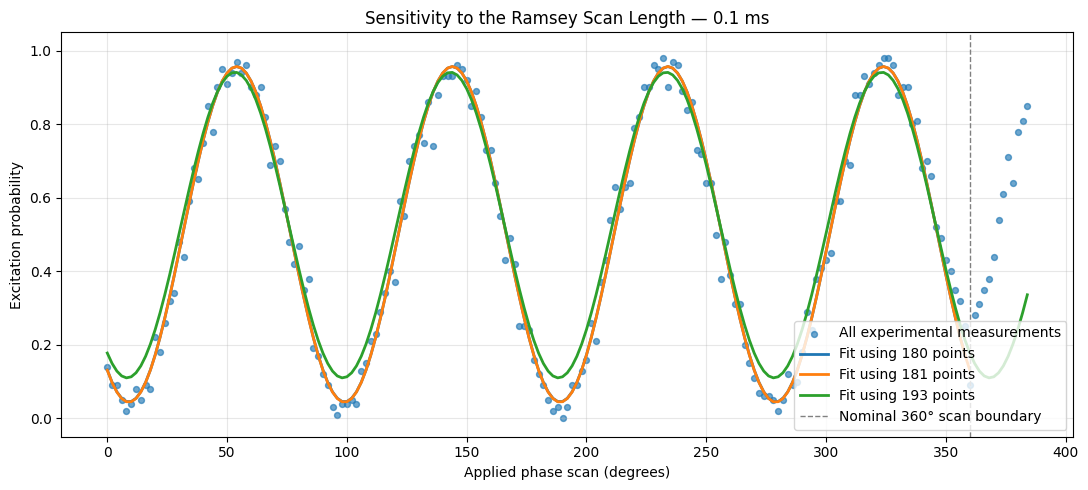

In [26]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

file_path = Path(
    "/content/ramsey_data/Ramsey/0+1/step_2_delay_0.1_ms.xlsx"
)

data = pd.read_excel(file_path)
probability = data["probability"].to_numpy(dtype=float)

PHASE_STEP_DEGREES = 2.0
CYCLE_COUNT = 4
SCAN_LENGTHS = [180, 181, len(probability)]

phase_degrees = np.arange(len(probability)) * PHASE_STEP_DEGREES
phase_radians = np.deg2rad(CYCLE_COUNT * phase_degrees)

design_matrix = np.column_stack([
    np.ones(len(probability)),
    np.cos(phase_radians),
    np.sin(phase_radians)
])


def fit_scan(point_count):
    observed = probability[:point_count]
    matrix = design_matrix[:point_count]

    coefficients, *_ = np.linalg.lstsq(
        matrix,
        observed,
        rcond=None
    )

    fitted = matrix @ coefficients
    residual_sum = np.sum((observed - fitted) ** 2)
    total_sum = np.sum((observed - observed.mean()) ** 2)

    r_squared = (
        1 - residual_sum / total_sum
        if total_sum > 0 else np.nan
    )

    contrast = 2 * np.hypot(coefficients[1], coefficients[2])

    common_fitted = design_matrix[:180] @ coefficients
    common_observed = probability[:180]

    common_residual_sum = np.sum(
        (common_observed - common_fitted) ** 2
    )
    common_total_sum = np.sum(
        (common_observed - common_observed.mean()) ** 2
    )

    common_r_squared = 1 - common_residual_sum / common_total_sum

    return {
        "coefficients": coefficients,
        "points_used": point_count,
        "points_beyond_180": max(point_count - 180, 0),
        "contrast": contrast,
        "R_squared": r_squared,
        "R_squared_on_common_180": common_r_squared
    }


results = [fit_scan(length) for length in SCAN_LENGTHS]

comparison = pd.DataFrame([
    {
        "Points used": result["points_used"],
        "Additional points beyond 180": result["points_beyond_180"],
        "Estimated contrast": result["contrast"],
        "Fit R-squared": result["R_squared"],
        "R-squared on common first 180": result["R_squared_on_common_180"]
    }
    for result in results
])

display(comparison.round(4))

plt.figure(figsize=(11, 5))

plt.scatter(
    phase_degrees,
    probability,
    s=18,
    alpha=0.65,
    label="All experimental measurements"
)

for result in results:
    coefficients = result["coefficients"]
    fitted = design_matrix @ coefficients
    point_count = result["points_used"]

    plt.plot(
        phase_degrees[:point_count],
        fitted[:point_count],
        linewidth=2,
        label=f"Fit using {point_count} points"
    )

plt.axvline(
    360,
    color="gray",
    linestyle="--",
    linewidth=1,
    label="Nominal 360° scan boundary"
)

plt.xlabel("Applied phase scan (degrees)")
plt.ylabel("Excitation probability")
plt.title("Sensitivity to the Ramsey Scan Length — 0.1 ms")
plt.ylim(-0.05, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [27]:

from pathlib import Path
import re

import pandas as pd

DATA_DIR = Path("/content/ramsey_data")

filename_pattern = re.compile(
    r"step_(?P<phase_step>[12])_delay_(?P<delay_ms>[\d.]+)_ms"
)


expected_points = {
    1: 360,
    2: 180
}

records = []

for file_path in sorted(DATA_DIR.rglob("*.xlsx")):
    match = filename_pattern.search(file_path.name)

    if match is None:
        continue

    data = pd.read_excel(file_path)
    point_count = len(data)

    phase_step = int(match["phase_step"])
    expected_count = expected_points[phase_step]

    if point_count < expected_count:
        scan_status = "Shorter than one full scan"
    elif point_count == expected_count:
        scan_status = "Expected scan length"
    elif point_count == expected_count + 1:
        scan_status = "One additional endpoint"
    else:
        scan_status = "Longer than expected"

    records.append({
        "State": file_path.parent.name,
        "Phase step": phase_step,
        "Delay (ms)": float(match["delay_ms"]),
        "Measurements": point_count,
        "Expected unique points": expected_count,
        "Scan status": scan_status,
        "File": file_path.name
    })

scan_audit = pd.DataFrame(records)

print(f"Files audited: {len(scan_audit)}")

print("\nScan-length summary:")
display(
    scan_audit
    .groupby(["Phase step", "Scan status"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

print("\nScan-length distribution:")
display(
    scan_audit
    .groupby(["Phase step", "Measurements"])
    .size()
    .reset_index(name="Number of files")
    .sort_values(["Phase step", "Measurements"])
)

print("\nFiles longer than expected by more than one point:")
display(
    scan_audit[
        scan_audit["Scan status"] == "Longer than expected"
    ][["State", "Phase step", "Delay (ms)", "Measurements", "File"]]
    .head(25)
)


Files audited: 177

Scan-length summary:


Scan status,Phase step,Expected scan length,Longer than expected,One additional endpoint,Shorter than one full scan
0,1,3,21,8,8
1,2,2,111,17,7



Scan-length distribution:


,Phase step,Measurements,Number of files
0,1,205,1
1,1,232,1
2,1,267,1
3,1,268,1
4,1,357,1
5,1,359,3
6,1,360,3
7,1,361,8
8,1,362,3
9,1,363,3



Files longer than expected by more than one point:


,State,Phase step,Delay (ms),Measurements,File
0,0+1,2,0.1,193,step_2_delay_0.1_ms.xlsx
1,0+1,2,0.2,182,step_2_delay_0.2_ms.xlsx
2,0+1,2,0.5,183,step_2_delay_0.5_ms.xlsx
6,0+1,2,20.0,182,step_2_delay_20_ms.xlsx
7,0+1,2,2.0,183,step_2_delay_2_ms.xlsx
8,0+1,2,40.0,182,step_2_delay_40_ms.xlsx
11,0+2,2,0.1,182,step_2_delay_0.1_ms.xlsx
12,0+2,2,0.2,206,step_2_delay_0.2_ms.xlsx
13,0+2,2,0.5,188,step_2_delay_0.5_ms.xlsx
14,0+2,2,10.0,182,step_2_delay_10_ms.xlsx


,Delay (ms),Original points,Points used,Extra points not used,Nominal phase coverage (degrees),Scan status,Contrast,R-squared
0,0.1,193,180,13,358.0,Complete-length window,0.9123,0.9833
1,0.2,182,180,2,358.0,Complete-length window,0.9275,0.9857
2,0.5,183,180,3,358.0,Complete-length window,0.9307,0.9884
5,1.0,181,180,1,358.0,Complete-length window,0.9464,0.9877
7,2.0,183,180,3,358.0,Complete-length window,0.9263,0.9759
9,5.0,181,180,1,358.0,Complete-length window,0.8759,0.9817
3,10.0,180,180,0,358.0,Complete-length window,0.8151,0.9607
6,20.0,182,180,2,358.0,Complete-length window,0.7075,0.9638
8,40.0,182,180,2,358.0,Complete-length window,0.5567,0.9052
10,80.0,169,169,0,336.0,Incomplete scan,0.1935,0.2491


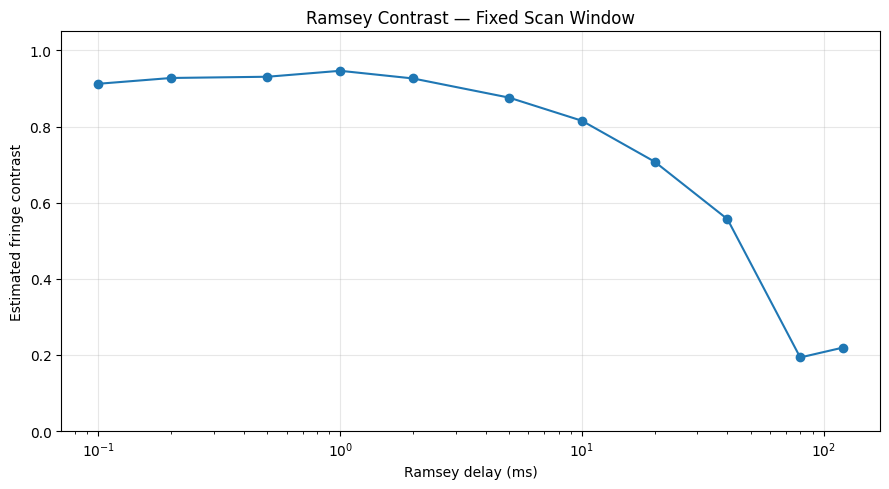

In [28]:

from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("/content/ramsey_data/Ramsey/0+1")

EXPECTED_POINTS = 180
PHASE_STEP_DEGREES = 2.0
EMPIRICAL_CYCLE_COUNT = 4

filename_pattern = re.compile(
    r"step_2_delay_(?P<delay>[\d.]+)_ms\.xlsx$"
)

records = []

for file_path in sorted(DATA_DIR.glob("step_2_delay_*_ms.xlsx")):
    match = filename_pattern.fullmatch(file_path.name)

    if match is None:
        continue

    data = pd.read_excel(file_path)
    probability = data["probability"].to_numpy(dtype=float)

    original_count = len(probability)
    used_count = min(original_count, EXPECTED_POINTS)

    probability = probability[:used_count]

    phase_degrees = (
        np.arange(used_count) * PHASE_STEP_DEGREES
    )

    effective_phase = np.deg2rad(
        EMPIRICAL_CYCLE_COUNT * phase_degrees
    )

    design_matrix = np.column_stack([
        np.ones(used_count),
        np.cos(effective_phase),
        np.sin(effective_phase)
    ])

    coefficients, *_ = np.linalg.lstsq(
        design_matrix,
        probability,
        rcond=None
    )

    fitted_probability = design_matrix @ coefficients

    residual_sum = np.sum(
        (probability - fitted_probability) ** 2
    )
    total_sum = np.sum(
        (probability - probability.mean()) ** 2
    )

    r_squared = (
        1 - residual_sum / total_sum
        if total_sum > 0 else np.nan
    )

    contrast = 2 * np.hypot(
        coefficients[1],
        coefficients[2]
    )

    records.append({
        "Delay (ms)": float(match["delay"]),
        "Original points": original_count,
        "Points used": used_count,
        "Extra points not used": max(
            original_count - EXPECTED_POINTS, 0
        ),
        "Nominal phase coverage (degrees)": (
            phase_degrees[-1] if used_count else np.nan
        ),
        "Scan status": (
            "Complete-length window"
            if original_count >= EXPECTED_POINTS
            else "Incomplete scan"
        ),
        "Contrast": contrast,
        "R-squared": r_squared
    })

summary = pd.DataFrame(records).sort_values("Delay (ms)")

display(summary.round(4))

plt.figure(figsize=(9, 5))

plt.plot(
    summary["Delay (ms)"],
    summary["Contrast"],
    "o-"
)

plt.xscale("log")
plt.xlabel("Ramsey delay (ms)")
plt.ylabel("Estimated fringe contrast")
plt.title("Ramsey Contrast — Fixed Scan Window")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


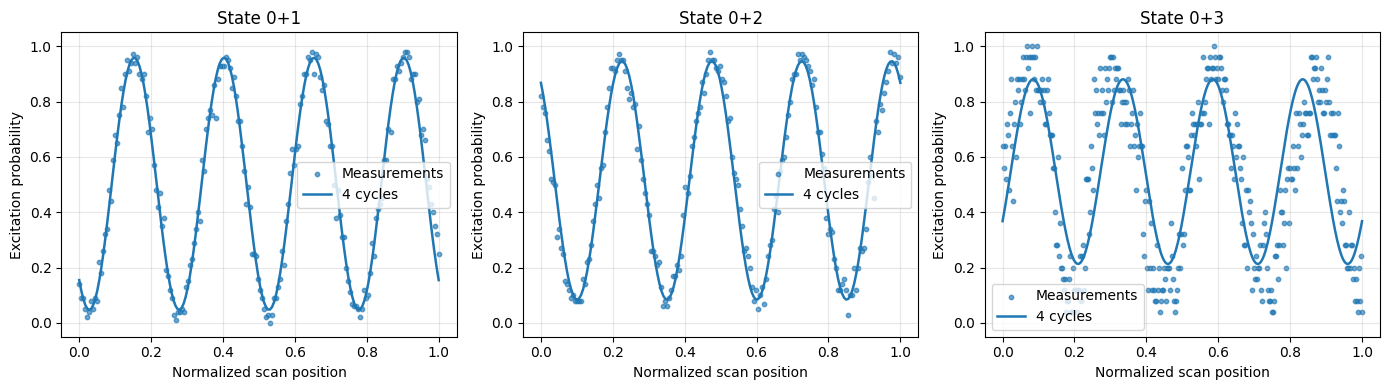

,State,Original points,Points used,Best cycle count,R-squared
0,0+1,193,180,4,0.9814
1,0+2,182,180,4,0.9768
2,0+3,361,360,4,0.6500


In [29]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("/content/ramsey_data/Ramsey")

experiments = [
    {
        "state": "0+1",
        "file": DATA_DIR / "0+1/step_2_delay_0.1_ms.xlsx",
        "expected_points": 180
    },
    {
        "state": "0+2",
        "file": DATA_DIR / "0+2/step_2_delay_0.1_ms.xlsx",
        "expected_points": 180
    },
    {
        "state": "0+3",
        "file": DATA_DIR / "0+3/step_1_delay_0.1_ms_repetitions_25_(0).xlsx",
        "expected_points": 360
    }
]

results = []
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for axis, experiment in zip(axes, experiments):
    data = pd.read_excel(experiment["file"])
    probability = data["probability"].to_numpy(dtype=float)

    expected_points = experiment["expected_points"]
    points_used = min(len(probability), expected_points)
    probability = probability[:points_used]

    scan_position = np.linspace(0, 1, points_used)
    best_fit = None

    for cycles in range(1, 11):
        phase = 2 * np.pi * cycles * scan_position

        design_matrix = np.column_stack([
            np.ones(points_used),
            np.cos(phase),
            np.sin(phase)
        ])

        coefficients, *_ = np.linalg.lstsq(
            design_matrix,
            probability,
            rcond=None
        )

        fitted = design_matrix @ coefficients
        residual_sum = np.sum((probability - fitted) ** 2)
        total_sum = np.sum(
            (probability - probability.mean()) ** 2
        )

        r_squared = (
            1 - residual_sum / total_sum
            if total_sum > 0 else np.nan
        )

        if best_fit is None or residual_sum < best_fit["rss"]:
            best_fit = {
                "cycles": cycles,
                "fitted": fitted,
                "rss": residual_sum,
                "r_squared": r_squared
            }

    results.append({
        "State": experiment["state"],
        "Original points": len(data),
        "Points used": points_used,
        "Best cycle count": best_fit["cycles"],
        "R-squared": best_fit["r_squared"]
    })

    axis.scatter(
        scan_position,
        probability,
        s=10,
        alpha=0.65,
        label="Measurements"
    )

    axis.plot(
        scan_position,
        best_fit["fitted"],
        linewidth=1.8,
        label=f"{best_fit['cycles']} cycles"
    )

    axis.set_title(f"State {experiment['state']}")
    axis.set_xlabel("Normalized scan position")
    axis.set_ylabel("Excitation probability")
    axis.set_ylim(-0.05, 1.05)
    axis.grid(alpha=0.3)
    axis.legend()

plt.tight_layout()
plt.show()

display(pd.DataFrame(results).round(4))


In [30]:

from pathlib import Path
import re

import pandas as pd

DATA_DIR = Path("/content/ramsey_data/Ramsey/0+3")

filename_pattern = re.compile(
    r"step_1_delay_0\.1_ms_repetitions_25_\((\d+)\)\.xlsx$"
)

records = []

for file_path in sorted(DATA_DIR.glob("*.xlsx")):
    match = filename_pattern.fullmatch(file_path.name)

    if match is None:
        continue

    data = pd.read_excel(file_path)
    probability = data["probability"]

    records.append({
        "Repeat index": int(match.group(1)),
        "File": file_path.name,
        "Measurements": len(data),
        "Missing values": probability.isna().sum(),
        "Minimum probability": probability.min(),
        "Maximum probability": probability.max()
    })

repeat_summary = (
    pd.DataFrame(records)
    .sort_values("Repeat index")
    .reset_index(drop=True)
)

print(f"Repeated scans found: {len(repeat_summary)}")
display(repeat_summary.round(4))


Repeated scans found: 6


,Repeat index,File,Measurements,Missing values,Minimum probability,Maximum probability
0,0,step_1_delay_0.1_ms_repetitions_25_(0).xlsx,361,0,0.04,1.00
1,1,step_1_delay_0.1_ms_repetitions_25_(1).xlsx,366,0,0.00,1.00
2,2,step_1_delay_0.1_ms_repetitions_25_(2).xlsx,359,0,0.00,1.00
3,3,step_1_delay_0.1_ms_repetitions_25_(3).xlsx,364,0,0.00,1.00
4,4,step_1_delay_0.1_ms_repetitions_25_(4).xlsx,362,0,0.00,0.96
5,5,step_1_delay_0.1_ms_repetitions_25_(5).xlsx,360,0,0.00,1.00


Repeated scans found: 6
Original lengths: [361, 366, 359, 364, 362, 360]
Shared measurement points: 359


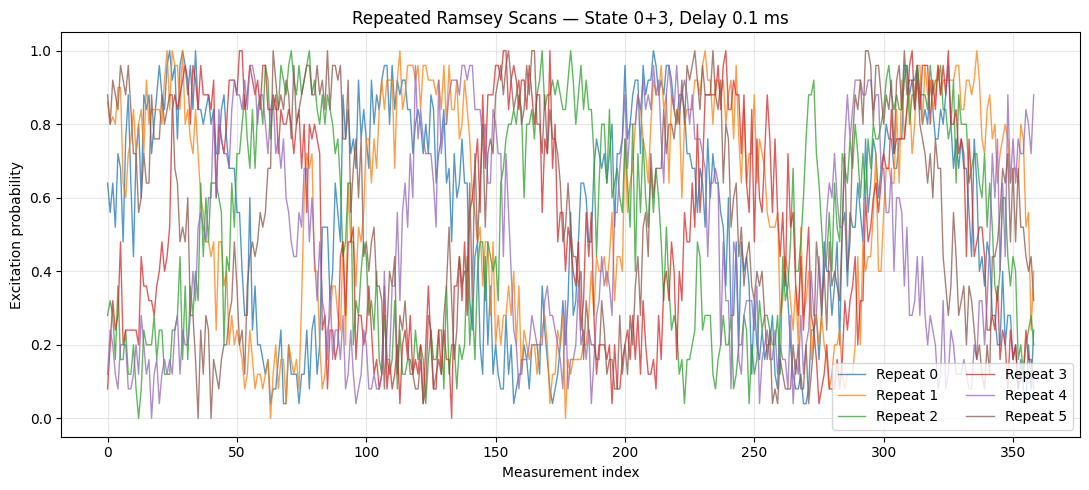

In [31]:

from pathlib import Path
import re

import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("/content/ramsey_data/Ramsey/0+3")

filename_pattern = re.compile(
    r"step_1_delay_0\.1_ms_repetitions_25_\((\d+)\)\.xlsx$"
)

repeated_scans = []

for file_path in DATA_DIR.glob("*.xlsx"):
    match = filename_pattern.fullmatch(file_path.name)

    if match is None:
        continue

    data = pd.read_excel(file_path)

    repeated_scans.append({
        "repeat_index": int(match.group(1)),
        "file": file_path.name,
        "probability": data["probability"].to_numpy(dtype=float)
    })

repeated_scans.sort(key=lambda scan: scan["repeat_index"])

if not repeated_scans:
    raise FileNotFoundError("No matching repeated scans were found.")

common_length = min(
    len(scan["probability"]) for scan in repeated_scans
)

print(f"Repeated scans found: {len(repeated_scans)}")
print("Original lengths:", [
    len(scan["probability"]) for scan in repeated_scans
])
print(f"Shared measurement points: {common_length}")

plt.figure(figsize=(11, 5))

for scan in repeated_scans:
    probability = scan["probability"][:common_length]

    plt.plot(
        range(common_length),
        probability,
        linewidth=1,
        alpha=0.75,
        label=f"Repeat {scan['repeat_index']}"
    )

plt.xlabel("Measurement index")
plt.ylabel("Excitation probability")
plt.title("Repeated Ramsey Scans — State 0+3, Delay 0.1 ms")
plt.ylim(-0.05, 1.05)
plt.grid(alpha=0.3)
plt.legend(ncol=2)
plt.tight_layout()
plt.show()


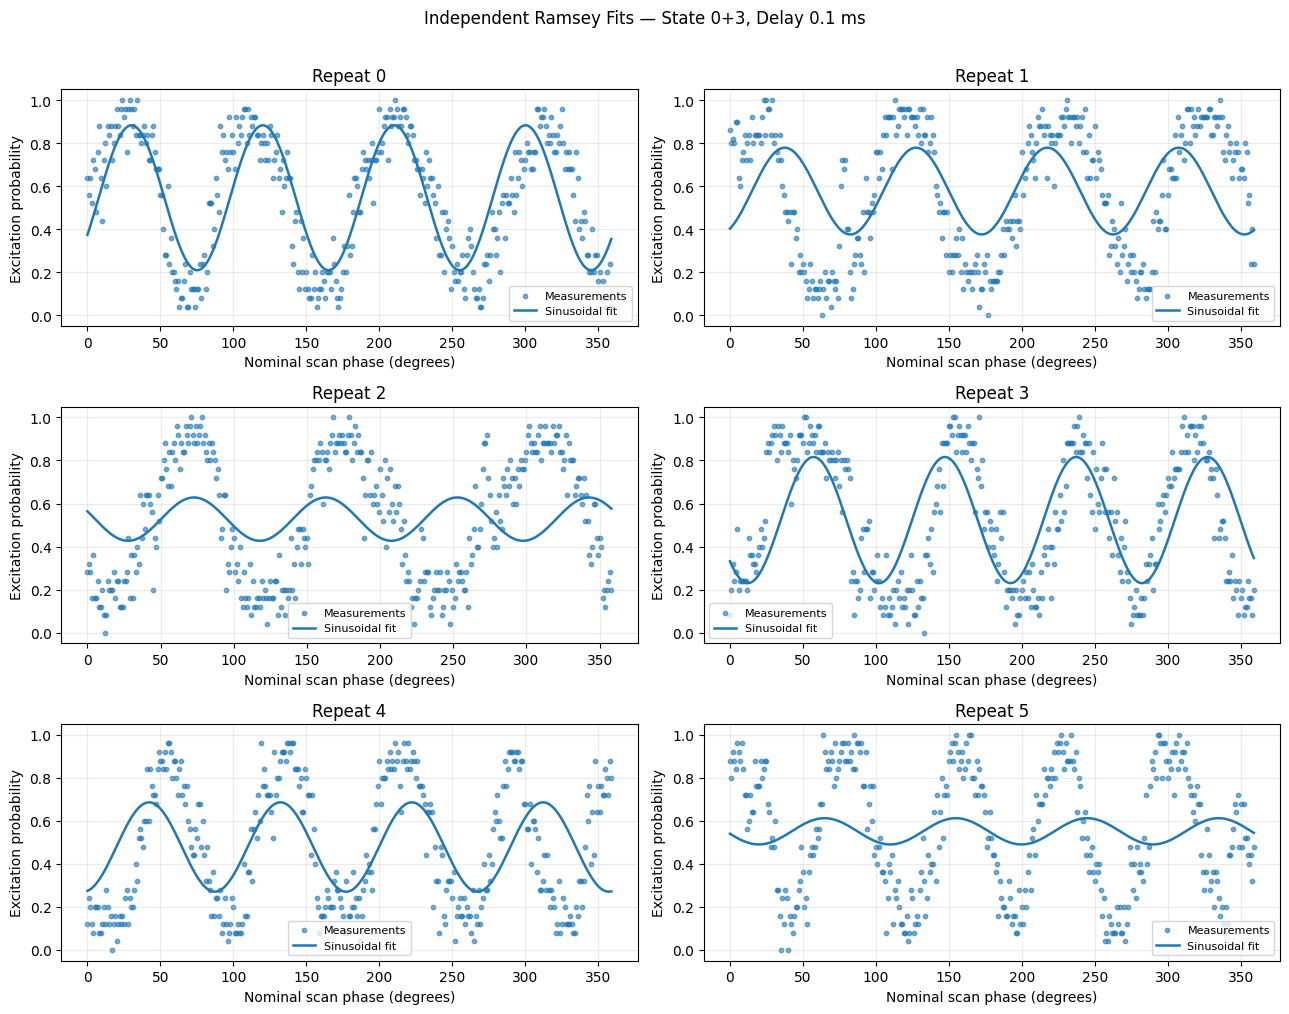

,Repeat,Original points,Points fitted,Offset,Contrast,Scan-phase shift (deg),R-squared
0,0,361,360,0.5462,0.6735,30.1732,0.6630
1,1,366,360,0.5772,0.4031,37.5205,0.2332
2,2,359,359,0.5274,0.2015,-17.2412,0.0620
3,3,364,360,0.5231,0.5861,-32.7265,0.4730
4,4,362,360,0.4783,0.4153,42.2350,0.2538
5,5,360,360,0.5513,0.1220,-25.1966,0.0216


In [32]:

from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("/content/ramsey_data/Ramsey/0+3")

filename_pattern = re.compile(
    r"step_1_delay_0\.1_ms_repetitions_25_\((\d+)\)\.xlsx$"
)

PHASE_STEP_DEGREES = 1.0
EMPIRICAL_CYCLE_COUNT = 4
EXPECTED_POINTS = 360

results = []
fig, axes = plt.subplots(3, 2, figsize=(13, 10))
axes = axes.flatten()

file_paths = sorted(
    [
        path for path in DATA_DIR.glob("*.xlsx")
        if filename_pattern.fullmatch(path.name)
    ],
    key=lambda path: int(filename_pattern.fullmatch(path.name).group(1))
)

if not file_paths:
    raise FileNotFoundError("No matching repeated scans were found.")

for axis, file_path in zip(axes, file_paths):
    match = filename_pattern.fullmatch(file_path.name)
    repeat_index = int(match.group(1))

    data = pd.read_excel(file_path)
    probability = data["probability"].to_numpy(dtype=float)

    point_count = min(len(probability), EXPECTED_POINTS)
    probability = probability[:point_count]

    phase_degrees = (
        np.arange(point_count) * PHASE_STEP_DEGREES
    )

    effective_phase = np.deg2rad(
        EMPIRICAL_CYCLE_COUNT * phase_degrees
    )

    design_matrix = np.column_stack([
        np.ones(point_count),
        np.cos(effective_phase),
        np.sin(effective_phase)
    ])

    coefficients, *_ = np.linalg.lstsq(
        design_matrix,
        probability,
        rcond=None
    )

    fitted_probability = design_matrix @ coefficients
    residuals = probability - fitted_probability

    residual_sum = np.sum(residuals ** 2)
    total_sum = np.sum(
        (probability - probability.mean()) ** 2
    )

    r_squared = (
        1 - residual_sum / total_sum
        if total_sum > 0 else np.nan
    )

    offset = coefficients[0]
    cosine_term = coefficients[1]
    sine_term = coefficients[2]

    amplitude = np.hypot(cosine_term, sine_term)
    contrast = 2 * amplitude

    effective_shift = np.degrees(
        np.arctan2(sine_term, cosine_term)
    )
    scan_phase_shift = effective_shift / EMPIRICAL_CYCLE_COUNT

    results.append({
        "Repeat": repeat_index,
        "Original points": len(data),
        "Points fitted": point_count,
        "Offset": offset,
        "Contrast": contrast,
        "Scan-phase shift (deg)": scan_phase_shift,
        "R-squared": r_squared
    })

    axis.scatter(
        phase_degrees,
        probability,
        s=10,
        alpha=0.6,
        label="Measurements"
    )

    axis.plot(
        phase_degrees,
        fitted_probability,
        linewidth=1.8,
        label="Sinusoidal fit"
    )

    axis.set_title(f"Repeat {repeat_index}")
    axis.set_xlabel("Nominal scan phase (degrees)")
    axis.set_ylabel("Excitation probability")
    axis.set_ylim(-0.05, 1.05)
    axis.grid(alpha=0.25)
    axis.legend(fontsize=8)

plt.suptitle(
    "Independent Ramsey Fits — State 0+3, Delay 0.1 ms",
    y=1.01
)
plt.tight_layout()
plt.show()

fit_summary = (
    pd.DataFrame(results)
    .sort_values("Repeat")
    .reset_index(drop=True)
)

display(fit_summary.round(4))


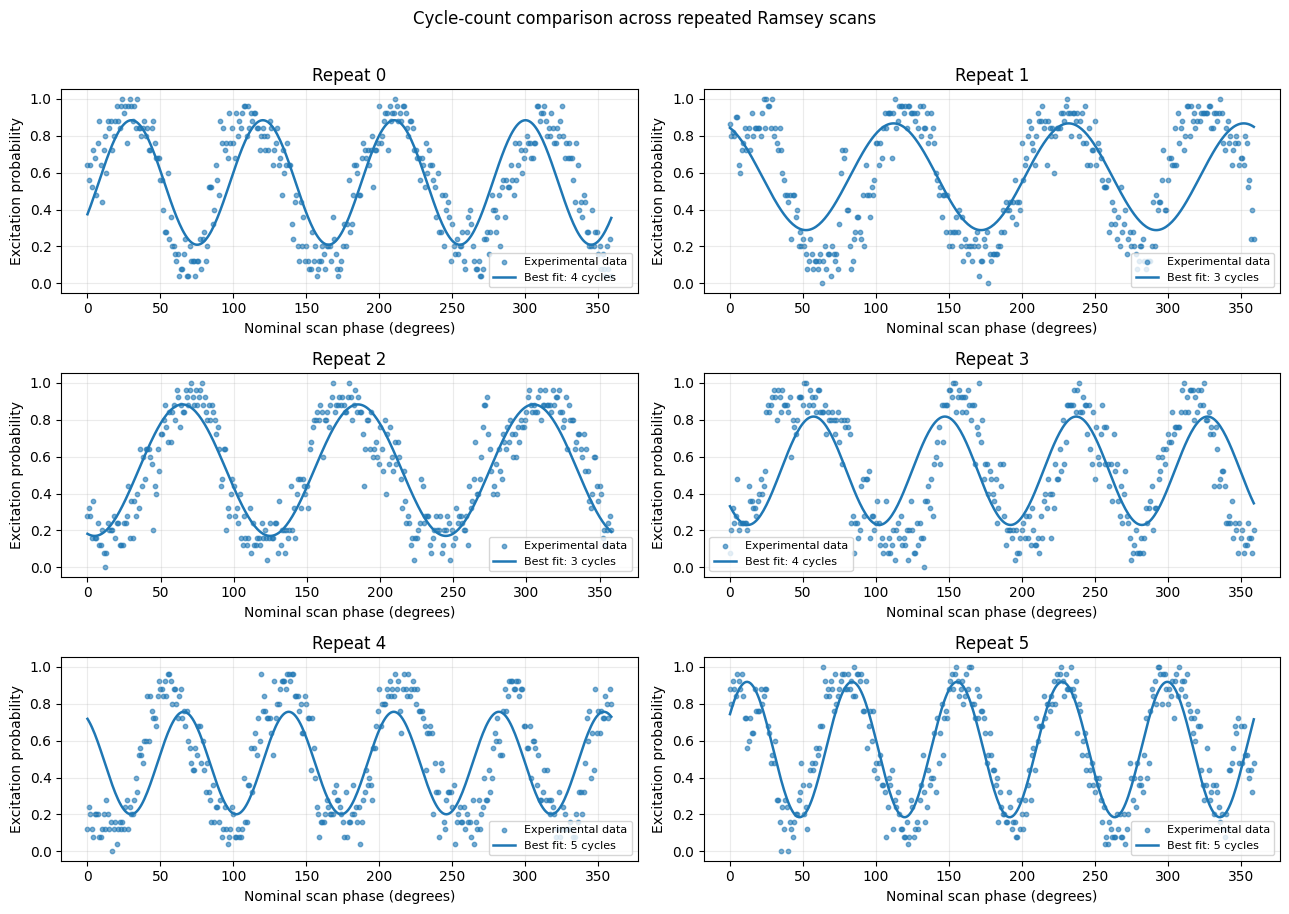

,Repeat,Original points,Points analyzed,Best cycle count,Best-fit R-squared,R-squared at 3 cycles,R-squared at 4 cycles,Contrast at best fit
0,0,361,360,4,0.6630,0.0986,0.6630,0.6735
1,1,366,360,3,0.4783,0.4783,0.2332,0.5772
2,2,359,359,3,0.7685,0.7685,0.0620,0.7112
3,3,364,360,4,0.4730,0.1714,0.4730,0.5861
4,4,362,360,5,0.4522,0.0073,0.2538,0.5543
5,5,360,360,5,0.7796,0.0395,0.0216,0.7321


In [35]:

from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("/content/ramsey_data/Ramsey/0+3")
EXPECTED_POINTS = 360
MAX_CYCLES = 10

filename_pattern = re.compile(
    r"step_1_delay_0\.1_ms_repetitions_25_\((\d+)\)\.xlsx$"
)

file_paths = []

for file_path in DATA_DIR.glob("*.xlsx"):
    match = filename_pattern.fullmatch(file_path.name)

    if match:
        file_paths.append((int(match.group(1)), file_path))

file_paths.sort(key=lambda item: item[0])

if not file_paths:
    raise FileNotFoundError(
        f"No repeated scans found in {DATA_DIR}"
    )

results = []
fig, axes = plt.subplots(3, 2, figsize=(13, 9))
axes = axes.flatten()

for axis, (repeat_index, file_path) in zip(axes, file_paths):
    data = pd.read_excel(file_path)
    probability = data["probability"].to_numpy(dtype=float)

    # Compare the same initial scan window for each repeat.
    probability = probability[:EXPECTED_POINTS]
    point_count = len(probability)

    phase_degrees = np.arange(point_count, dtype=float)
    candidate_fits = []

    for cycles in range(1, MAX_CYCLES + 1):
        phase = np.deg2rad(cycles * phase_degrees)

        design_matrix = np.column_stack([
            np.ones(point_count),
            np.cos(phase),
            np.sin(phase)
        ])

        coefficients, *_ = np.linalg.lstsq(
            design_matrix,
            probability,
            rcond=None
        )

        fitted = design_matrix @ coefficients
        residual_sum = np.sum((probability - fitted) ** 2)
        total_sum = np.sum(
            (probability - probability.mean()) ** 2
        )

        r_squared = (
            1 - residual_sum / total_sum
            if total_sum > 0 else np.nan
        )

        contrast = 2 * np.hypot(
            coefficients[1],
            coefficients[2]
        )

        candidate_fits.append({
            "cycles": cycles,
            "fitted": fitted,
            "r_squared": r_squared,
            "contrast": contrast
        })

    best_fit = max(
        candidate_fits,
        key=lambda result: result["r_squared"]
    )

    fit_3 = next(
        fit for fit in candidate_fits if fit["cycles"] == 3
    )
    fit_4 = next(
        fit for fit in candidate_fits if fit["cycles"] == 4
    )

    results.append({
        "Repeat": repeat_index,
        "Original points": len(data),
        "Points analyzed": point_count,
        "Best cycle count": best_fit["cycles"],
        "Best-fit R-squared": best_fit["r_squared"],
        "R-squared at 3 cycles": fit_3["r_squared"],
        "R-squared at 4 cycles": fit_4["r_squared"],
        "Contrast at best fit": best_fit["contrast"]
    })

    axis.scatter(
        phase_degrees,
        probability,
        s=10,
        alpha=0.6,
        label="Experimental data"
    )

    axis.plot(
        phase_degrees,
        best_fit["fitted"],
        linewidth=1.8,
        label=f"Best fit: {best_fit['cycles']} cycles"
    )

    axis.set_title(f"Repeat {repeat_index}")
    axis.set_xlabel("Nominal scan phase (degrees)")
    axis.set_ylabel("Excitation probability")
    axis.set_ylim(-0.05, 1.05)
    axis.grid(alpha=0.25)
    axis.legend(fontsize=8)

plt.suptitle(
    "Cycle-count comparison across repeated Ramsey scans",
    y=1.01
)
plt.tight_layout()
plt.show()

fit_summary = pd.DataFrame(results).sort_values("Repeat")
display(fit_summary.round(4))


,Delay (ms),Original points,Points fitted,Scan status,Fitted offset,Contrast,Approx. contrast SE,R-squared
0,0.1,193,180,Complete-length window,0.5008,0.9123,0.0089,0.9833
1,0.2,182,180,Complete-length window,0.4958,0.9275,0.0084,0.9857
2,0.5,183,180,Complete-length window,0.4967,0.9307,0.0076,0.9884
3,1.0,181,180,Complete-length window,0.4906,0.9464,0.0079,0.9877
4,2.0,183,180,Complete-length window,0.4858,0.9263,0.0109,0.9759
5,5.0,181,180,Complete-length window,0.4831,0.8759,0.0090,0.9817
6,10.0,180,180,Complete-length window,0.4752,0.8151,0.0124,0.9607
7,20.0,182,180,Complete-length window,0.4471,0.7075,0.0103,0.9638
8,40.0,182,180,Complete-length window,0.4262,0.5567,0.0135,0.9052
9,80.0,169,169,Incomplete scan,0.3874,0.1935,0.0261,0.2491


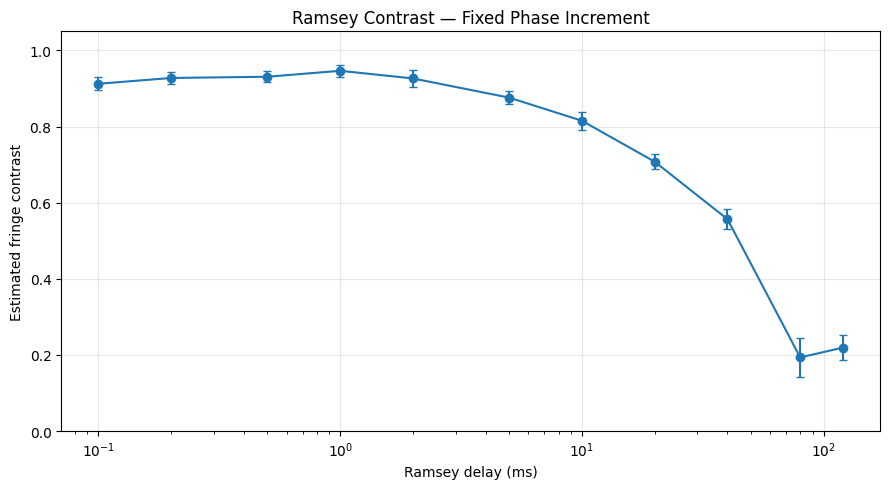

In [36]:

from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("/content/ramsey_data/Ramsey/0+1")

PHASE_STEP_DEGREES = 2.0
EMPIRICAL_CYCLES = 4
EXPECTED_POINTS = 180

filename_pattern = re.compile(
    r"step_2_delay_(?P<delay>[\d.]+)_ms\.xlsx$"
)

records = []

for file_path in sorted(DATA_DIR.glob("step_2_delay_*_ms.xlsx")):
    match = filename_pattern.fullmatch(file_path.name)

    if match is None:
        continue

    data = pd.read_excel(file_path)
    original_probability = data["probability"].to_numpy(dtype=float)

    # Use a common scan window where available.
    point_count = min(len(original_probability), EXPECTED_POINTS)
    probability = original_probability[:point_count]

    nominal_phase = (
        np.arange(point_count) * PHASE_STEP_DEGREES
    )
    effective_phase = np.deg2rad(
        EMPIRICAL_CYCLES * nominal_phase
    )

    design_matrix = np.column_stack([
        np.ones(point_count),
        np.cos(effective_phase),
        np.sin(effective_phase)
    ])

    coefficients, *_ = np.linalg.lstsq(
        design_matrix,
        probability,
        rcond=None
    )

    fitted_probability = design_matrix @ coefficients
    residuals = probability - fitted_probability

    residual_sum = np.sum(residuals ** 2)
    total_sum = np.sum(
        (probability - probability.mean()) ** 2
    )

    r_squared = (
        1 - residual_sum / total_sum
        if total_sum > 0 else np.nan
    )

    offset = coefficients[0]
    cosine_term, sine_term = coefficients[1:3]
    amplitude = np.hypot(cosine_term, sine_term)
    contrast = 2 * amplitude

    # Approximate uncertainty conditional on this sinusoidal model.
    degrees_of_freedom = point_count - design_matrix.shape[1]
    residual_variance = residual_sum / degrees_of_freedom

    coefficient_covariance = residual_variance * np.linalg.inv(
        design_matrix.T @ design_matrix
    )

    if amplitude > 0:
        gradient = 2 * np.array([
            cosine_term / amplitude,
            sine_term / amplitude
        ])

        contrast_variance = (
            gradient
            @ coefficient_covariance[1:3, 1:3]
            @ gradient
        )
        contrast_se = np.sqrt(max(contrast_variance, 0))
    else:
        contrast_se = np.nan

    records.append({
        "Delay (ms)": float(match["delay"]),
        "Original points": len(original_probability),
        "Points fitted": point_count,
        "Scan status": (
            "Complete-length window"
            if len(original_probability) >= EXPECTED_POINTS
            else "Incomplete scan"
        ),
        "Fitted offset": offset,
        "Contrast": contrast,
        "Approx. contrast SE": contrast_se,
        "R-squared": r_squared
    })

contrast_summary = (
    pd.DataFrame(records)
    .sort_values("Delay (ms)")
    .reset_index(drop=True)
)

display(contrast_summary.round(4))

plt.figure(figsize=(9, 5))

plt.errorbar(
    contrast_summary["Delay (ms)"],
    contrast_summary["Contrast"],
    yerr=1.96 * contrast_summary["Approx. contrast SE"],
    fmt="o-",
    capsize=3
)

plt.xscale("log")
plt.xlabel("Ramsey delay (ms)")
plt.ylabel("Estimated fringe contrast")
plt.title("Ramsey Contrast — Fixed Phase Increment")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


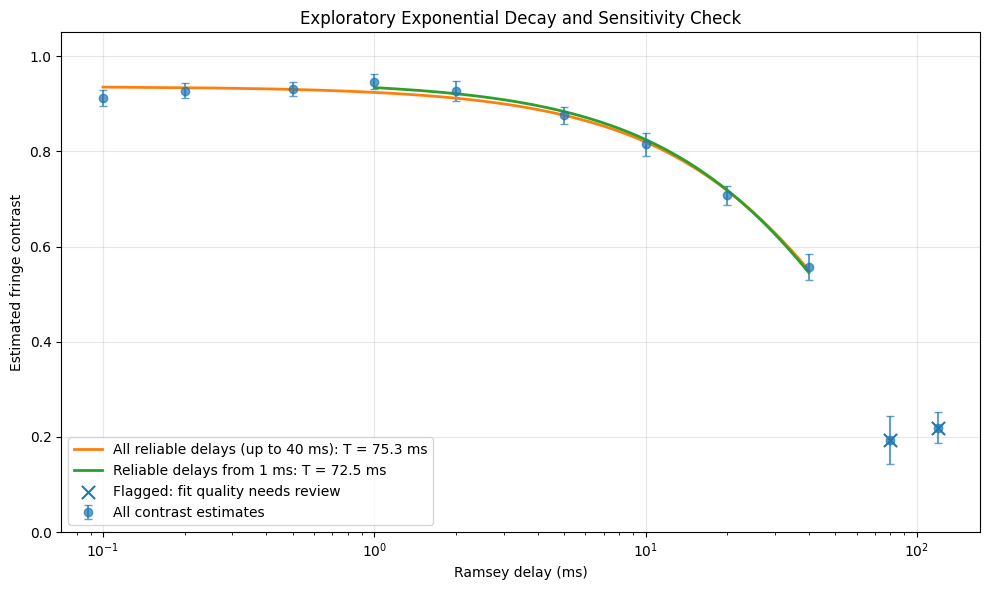

,Analysis,Points fitted,Initial contrast,Decay time (ms),Approx. decay-time SE (ms),RMSE,R-squared
0,All reliable delays (up to 40 ms),9,0.9362,75.2751,3.3684,0.0126,0.9897
1,Reliable delays from 1 ms,6,0.9468,72.4775,2.9786,0.0099,0.9947



Measurements flagged for review:


,Delay (ms),Contrast,R-squared,Scan status
9,80.0,0.1935,0.2491,Incomplete scan
10,120.0,0.2193,0.4998,Complete-length window


In [37]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

data = contrast_summary.copy().sort_values("Delay (ms)")

reliable_data = data[
    (data["R-squared"] >= 0.90)
    & (data["Delay (ms)"] <= 40)
].copy()


def exponential_decay(time_ms, initial_contrast, decay_time_ms):
    return initial_contrast * np.exp(-time_ms / decay_time_ms)


analysis_groups = {
    "All reliable delays (up to 40 ms)": reliable_data,
    "Reliable delays from 1 ms": reliable_data[
        reliable_data["Delay (ms)"] >= 1
    ]
}

fit_records = []

plt.figure(figsize=(10, 6))

plt.errorbar(
    data["Delay (ms)"],
    data["Contrast"],
    yerr=1.96 * data["Approx. contrast SE"],
    fmt="o",
    capsize=3,
    alpha=0.7,
    label="All contrast estimates"
)

for group_name, group in analysis_groups.items():
    time_ms = group["Delay (ms)"].to_numpy(dtype=float)
    contrast = group["Contrast"].to_numpy(dtype=float)

    parameters, covariance = curve_fit(
        exponential_decay,
        time_ms,
        contrast,
        p0=[0.95, 70],
        bounds=([0.0, 0.1], [1.2, 1000]),
        maxfev=20000
    )

    initial_contrast, decay_time_ms = parameters
    predicted = exponential_decay(time_ms, *parameters)

    residuals = contrast - predicted
    rmse = np.sqrt(np.mean(residuals ** 2))

    total_sum = np.sum((contrast - contrast.mean()) ** 2)
    r_squared = (
        1 - np.sum(residuals ** 2) / total_sum
        if total_sum > 0 else np.nan
    )

    decay_time_se = np.sqrt(covariance[1, 1])

    fit_records.append({
        "Analysis": group_name,
        "Points fitted": len(group),
        "Initial contrast": initial_contrast,
        "Decay time (ms)": decay_time_ms,
        "Approx. decay-time SE (ms)": decay_time_se,
        "RMSE": rmse,
        "R-squared": r_squared
    })

    time_grid = np.linspace(time_ms.min(), time_ms.max(), 250)

    plt.plot(
        time_grid,
        exponential_decay(time_grid, *parameters),
        linewidth=2,
        label=f"{group_name}: T = {decay_time_ms:.1f} ms"
    )

flagged = data[
    (data["R-squared"] < 0.90)
    | (data["Delay (ms)"] > 40)
]

plt.scatter(
    flagged["Delay (ms)"],
    flagged["Contrast"],
    marker="x",
    s=90,
    label="Flagged: fit quality needs review"
)

plt.xscale("log")
plt.xlabel("Ramsey delay (ms)")
plt.ylabel("Estimated fringe contrast")
plt.title("Exploratory Exponential Decay and Sensitivity Check")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

fit_summary = pd.DataFrame(fit_records)
display(fit_summary.round(4))

print("\nMeasurements flagged for review:")
display(
    flagged[
        ["Delay (ms)", "Contrast", "R-squared", "Scan status"]
    ].round(4)
)


Weighted exponential fit:


,Points fitted,Initial contrast,Decay time (ms),Approx. decay-time SE (ms),Approx. 95% CI lower (ms),Approx. 95% CI upper (ms),Reduced chi-squared
0,9,0.9369,74.6571,2.7199,69.3261,79.988,2.5822


Residual diagnostics:


,Delay (ms),Observed contrast,Predicted contrast,Residual,Contrast SE,Standardized residual
0,0.1,0.9123,0.9357,-0.0234,0.0089,-2.6131
1,0.2,0.9275,0.9344,-0.0069,0.0084,-0.8246
2,0.5,0.9307,0.9307,0.0000,0.0076,0.0059
3,1.0,0.9464,0.9245,0.0219,0.0079,2.7567
4,2.0,0.9263,0.9122,0.0141,0.0109,1.2881
5,5.0,0.8759,0.8762,-0.0004,0.0090,-0.0417
6,10.0,0.8151,0.8195,-0.0043,0.0124,-0.3506
7,20.0,0.7075,0.7168,-0.0092,0.0103,-0.8938
8,40.0,0.5567,0.5483,0.0084,0.0135,0.6200


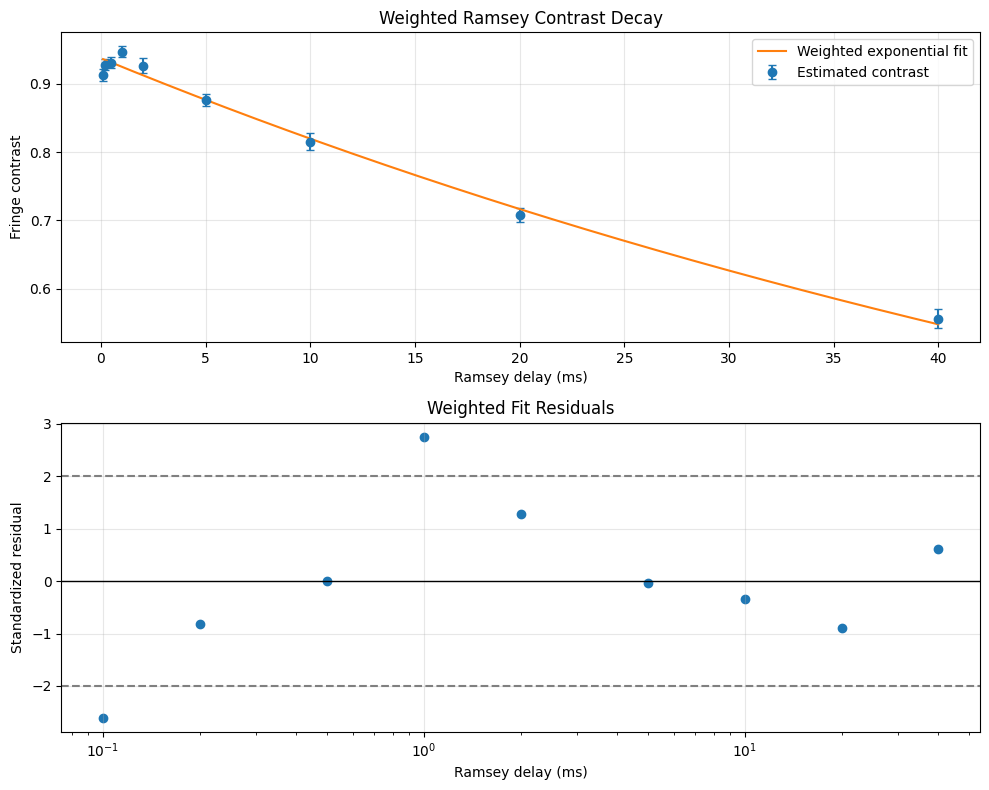

In [38]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

data = contrast_summary[
    (contrast_summary["R-squared"] >= 0.90)
    & (contrast_summary["Delay (ms)"] <= 40)
].copy()

data = data.sort_values("Delay (ms)").reset_index(drop=True)

delay = data["Delay (ms)"].to_numpy(dtype=float)
contrast = data["Contrast"].to_numpy(dtype=float)
contrast_se = data["Approx. contrast SE"].to_numpy(dtype=float)


def exponential_decay(time_ms, initial_contrast, decay_time_ms):
    return initial_contrast * np.exp(-time_ms / decay_time_ms)


parameters, covariance = curve_fit(
    exponential_decay,
    delay,
    contrast,
    p0=[0.95, 75],
    sigma=contrast_se,
    absolute_sigma=True,
    bounds=([0.0, 0.1], [1.2, 1000]),
    maxfev=20000
)

initial_contrast, decay_time = parameters
parameter_se = np.sqrt(np.diag(covariance))

predicted = exponential_decay(delay, *parameters)
residuals = contrast - predicted
standardized_residuals = residuals / contrast_se

chi_squared = np.sum(standardized_residuals ** 2)
degrees_of_freedom = len(delay) - len(parameters)
reduced_chi_squared = chi_squared / degrees_of_freedom

diagnostics = pd.DataFrame({
    "Delay (ms)": delay,
    "Observed contrast": contrast,
    "Predicted contrast": predicted,
    "Residual": residuals,
    "Contrast SE": contrast_se,
    "Standardized residual": standardized_residuals
})

fit_metrics = pd.DataFrame([{
    "Points fitted": len(delay),
    "Initial contrast": initial_contrast,
    "Decay time (ms)": decay_time,
    "Approx. decay-time SE (ms)": parameter_se[1],
    "Approx. 95% CI lower (ms)": max(
        0, decay_time - 1.96 * parameter_se[1]
    ),
    "Approx. 95% CI upper (ms)": (
        decay_time + 1.96 * parameter_se[1]
    ),
    "Reduced chi-squared": reduced_chi_squared
}])

print("Weighted exponential fit:")
display(fit_metrics.round(4))

print("Residual diagnostics:")
display(diagnostics.round(4))

fig, axes = plt.subplots(2, 1, figsize=(10, 8))

time_grid = np.linspace(delay.min(), delay.max(), 300)

axes[0].errorbar(
    delay,
    contrast,
    yerr=contrast_se,
    fmt="o",
    capsize=3,
    label="Estimated contrast"
)

axes[0].plot(
    time_grid,
    exponential_decay(time_grid, *parameters),
    label="Weighted exponential fit"
)

axes[0].set_xlabel("Ramsey delay (ms)")
axes[0].set_ylabel("Fringe contrast")
axes[0].set_title("Weighted Ramsey Contrast Decay")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].axhline(0, color="black", linewidth=1)
axes[1].axhline(2, color="gray", linestyle="--")
axes[1].axhline(-2, color="gray", linestyle="--")

axes[1].scatter(delay, standardized_residuals)
axes[1].set_xscale("log")
axes[1].set_xlabel("Ramsey delay (ms)")
axes[1].set_ylabel("Standardized residual")
axes[1].set_title("Weighted Fit Residuals")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


Full-data decay time: 74.657 ms
Leave-one-out decay-time range: 72.144–76.828 ms


,Delay omitted (ms),Full-data decay time (ms),Leave-one-out decay time (ms),Change in decay time (ms),Reduced chi-squared
0,0.1,74.6571,73.1105,-1.5466,1.6385
1,0.2,74.6571,74.1329,-0.5242,2.8722
2,0.5,74.6571,74.6610,0.0040,3.0125
3,1.0,74.6571,76.1110,1.4539,1.4400
4,2.0,74.6571,74.9241,0.2670,2.7078
5,5.0,74.6571,74.6652,0.0081,3.0122
6,10.0,74.6571,74.8732,0.2161,2.9899
7,20.0,74.6571,76.8281,2.1711,2.8022
8,40.0,74.6571,72.1439,-2.5131,2.8750


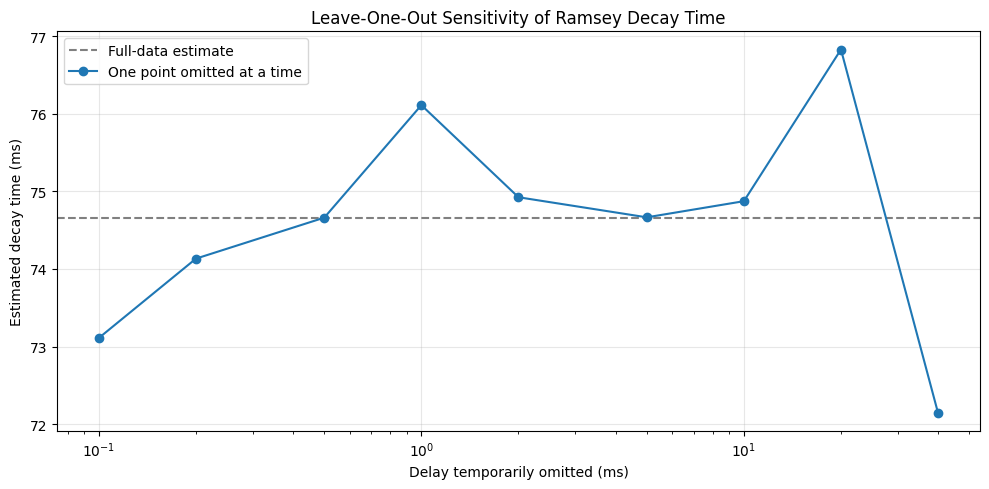

In [39]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

data = contrast_summary[
    (contrast_summary["R-squared"] >= 0.90)
    & (contrast_summary["Delay (ms)"] <= 40)
].copy()

data = data.sort_values("Delay (ms)").reset_index(drop=True)

delay = data["Delay (ms)"].to_numpy(dtype=float)
contrast = data["Contrast"].to_numpy(dtype=float)
contrast_se = data["Approx. contrast SE"].to_numpy(dtype=float)


def exponential_decay(time_ms, initial_contrast, decay_time_ms):
    return initial_contrast * np.exp(-time_ms / decay_time_ms)


def fit_decay(time_ms, measured_contrast, uncertainty):
    parameters, covariance = curve_fit(
        exponential_decay,
        time_ms,
        measured_contrast,
        sigma=uncertainty,
        absolute_sigma=True,
        p0=[0.95, 75],
        bounds=([0.0, 0.1], [1.2, 1000]),
        maxfev=20000
    )

    predicted = exponential_decay(time_ms, *parameters)
    residuals = measured_contrast - predicted

    chi_squared = np.sum((residuals / uncertainty) ** 2)
    degrees_of_freedom = len(time_ms) - len(parameters)

    return {
        "initial_contrast": parameters[0],
        "decay_time_ms": parameters[1],
        "decay_time_se_ms": np.sqrt(covariance[1, 1]),
        "reduced_chi_squared": (
            chi_squared / degrees_of_freedom
            if degrees_of_freedom > 0 else np.nan
        )
    }


full_fit = fit_decay(delay, contrast, contrast_se)

results = []

for index in range(len(data)):
    keep = np.arange(len(data)) != index

    reduced_fit = fit_decay(
        delay[keep],
        contrast[keep],
        contrast_se[keep]
    )

    results.append({
        "Delay omitted (ms)": delay[index],
        "Full-data decay time (ms)": full_fit["decay_time_ms"],
        "Leave-one-out decay time (ms)": reduced_fit["decay_time_ms"],
        "Change in decay time (ms)": (
            reduced_fit["decay_time_ms"]
            - full_fit["decay_time_ms"]
        ),
        "Reduced chi-squared": reduced_fit["reduced_chi_squared"]
    })

sensitivity = pd.DataFrame(results)

print(f"Full-data decay time: {full_fit['decay_time_ms']:.3f} ms")
print(
    "Leave-one-out decay-time range: "
    f"{sensitivity['Leave-one-out decay time (ms)'].min():.3f}–"
    f"{sensitivity['Leave-one-out decay time (ms)'].max():.3f} ms"
)

display(sensitivity.round(4))

plt.figure(figsize=(10, 5))

plt.axhline(
    full_fit["decay_time_ms"],
    color="gray",
    linestyle="--",
    label="Full-data estimate"
)

plt.plot(
    sensitivity["Delay omitted (ms)"],
    sensitivity["Leave-one-out decay time (ms)"],
    "o-",
    label="One point omitted at a time"
)

plt.xscale("log")
plt.xlabel("Delay temporarily omitted (ms)")
plt.ylabel("Estimated decay time (ms)")
plt.title("Leave-One-Out Sensitivity of Ramsey Decay Time")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


,Model,Parameters,Weighted chi-squared,Reduced chi-squared,AICc,Initial contrast,Decay time (ms),Decay-time SE (ms),Stretch exponent
0,Exponential,2,18.0753,2.5822,24.0753,0.9369,74.6571,2.7199,NaN
2,Stretched exponential,3,17.9946,2.9991,28.7946,0.9362,73.4710,5.1506,1.0176
1,Gaussian,2,139.6303,19.9472,145.6303,0.9129,51.1263,1.0498,NaN


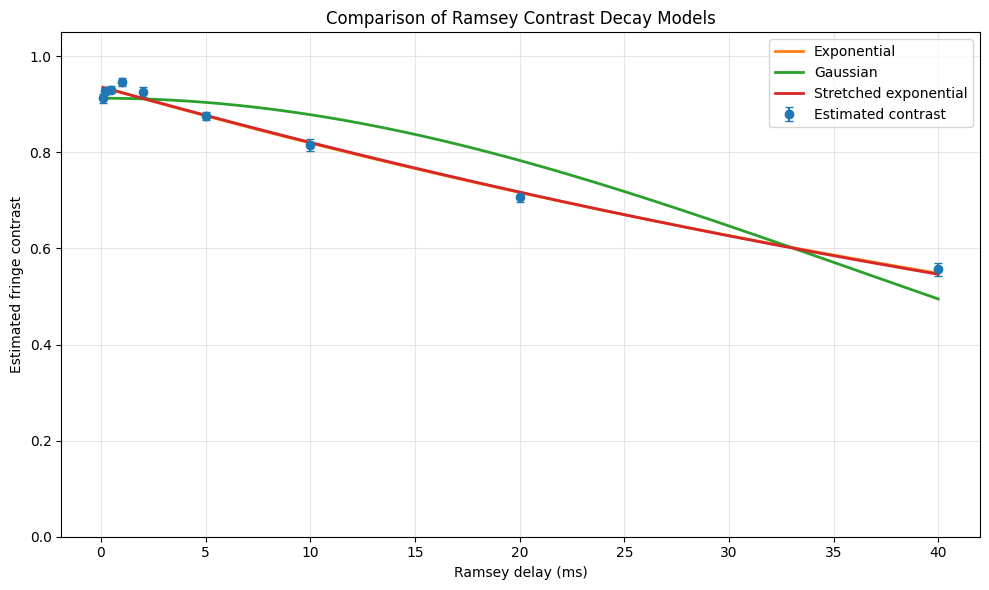

In [40]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

data = contrast_summary[
    (contrast_summary["R-squared"] >= 0.90)
    & (contrast_summary["Delay (ms)"] <= 40)
].copy()

data = data.sort_values("Delay (ms)").reset_index(drop=True)

delay = data["Delay (ms)"].to_numpy(dtype=float)
contrast = data["Contrast"].to_numpy(dtype=float)
uncertainty = data["Approx. contrast SE"].to_numpy(dtype=float)


def exponential_decay(time_ms, initial_contrast, decay_time):
    return initial_contrast * np.exp(-time_ms / decay_time)


def gaussian_decay(time_ms, initial_contrast, decay_time):
    return initial_contrast * np.exp(-(time_ms / decay_time) ** 2)


def stretched_exponential(time_ms, initial_contrast, decay_time, exponent):
    return initial_contrast * np.exp(
        -(time_ms / decay_time) ** exponent
    )


models = {
    "Exponential": {
        "function": exponential_decay,
        "initial_guess": [0.95, 75],
        "bounds": ([0, 0.1], [1.2, 1000])
    },
    "Gaussian": {
        "function": gaussian_decay,
        "initial_guess": [0.95, 75],
        "bounds": ([0, 0.1], [1.2, 1000])
    },
    "Stretched exponential": {
        "function": stretched_exponential,
        "initial_guess": [0.95, 75, 1.2],
        "bounds": ([0, 0.1, 0.25], [1.2, 1000, 3.0])
    }
}

fit_results = []
fitted_curves = {}

for model_name, settings in models.items():
    parameters, covariance = curve_fit(
        settings["function"],
        delay,
        contrast,
        p0=settings["initial_guess"],
        sigma=uncertainty,
        absolute_sigma=True,
        bounds=settings["bounds"],
        maxfev=30000
    )

    predicted = settings["function"](delay, *parameters)
    standardized_residuals = (contrast - predicted) / uncertainty

    chi_squared = np.sum(standardized_residuals ** 2)
    degrees_of_freedom = len(delay) - len(parameters)
    reduced_chi_squared = chi_squared / degrees_of_freedom

    parameter_count = len(parameters)
    sample_count = len(delay)

    aicc = (
        chi_squared
        + 2 * parameter_count
        + (
            2 * parameter_count * (parameter_count + 1)
            / (sample_count - parameter_count - 1)
        )
    )

    standard_errors = np.sqrt(np.diag(covariance))

    row = {
        "Model": model_name,
        "Parameters": parameter_count,
        "Weighted chi-squared": chi_squared,
        "Reduced chi-squared": reduced_chi_squared,
        "AICc": aicc,
        "Initial contrast": parameters[0],
        "Decay time (ms)": parameters[1],
        "Decay-time SE (ms)": standard_errors[1]
    }

    if model_name == "Stretched exponential":
        row["Stretch exponent"] = parameters[2]

    fit_results.append(row)
    fitted_curves[model_name] = (settings["function"], parameters)

comparison = pd.DataFrame(fit_results).sort_values("AICc")
display(comparison.round(4))

time_grid = np.linspace(delay.min(), delay.max(), 300)

plt.figure(figsize=(10, 6))

plt.errorbar(
    delay,
    contrast,
    yerr=uncertainty,
    fmt="o",
    capsize=3,
    label="Estimated contrast"
)

for model_name, (model_function, parameters) in fitted_curves.items():
    plt.plot(
        time_grid,
        model_function(time_grid, *parameters),
        linewidth=2,
        label=model_name
    )

plt.xlabel("Ramsey delay (ms)")
plt.ylabel("Estimated fringe contrast")
plt.title("Comparison of Ramsey Contrast Decay Models")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


,Delay (ms),Original points,Points analyzed,Best empirical cycles,Estimated contrast,R-squared
0,0.1,193,180,3.975,0.9124,0.9833
1,0.2,182,180,3.965,0.9263,0.9863
2,0.5,183,180,3.985,0.9306,0.9886
5,1.0,181,180,3.965,0.9481,0.9882
7,2.0,183,180,3.935,0.9307,0.9821
9,5.0,181,180,3.970,0.8764,0.9819
3,10.0,180,180,4.045,0.8212,0.9742
6,20.0,182,180,3.950,0.7101,0.9658
8,40.0,182,180,3.950,0.5574,0.9072
4,120.0,181,180,4.340,0.2628,0.7266


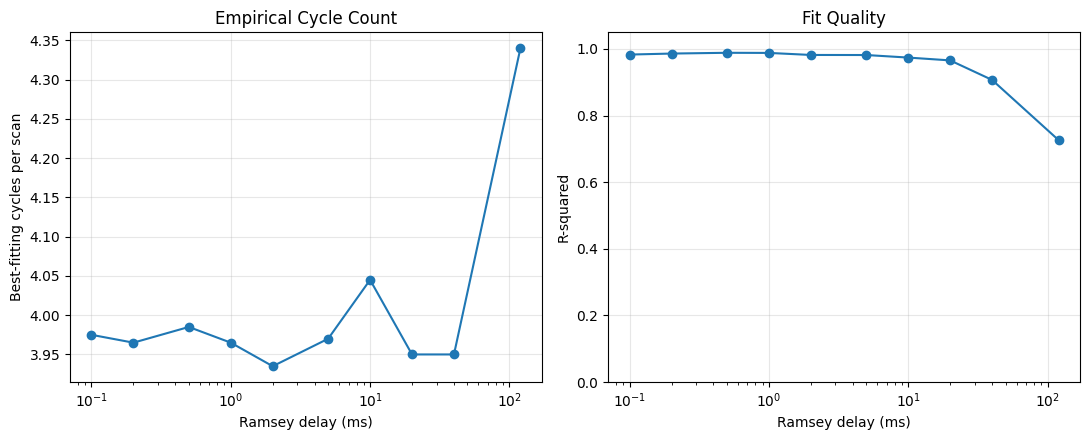

In [41]:

from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("/content/ramsey_data/Ramsey/0+1")
EXPECTED_POINTS = 180

filename_pattern = re.compile(
    r"step_2_delay_(?P<delay>[\d.]+)_ms\.xlsx$"
)

cycle_grid = np.linspace(1, 10, 1801)
results = []

for file_path in sorted(DATA_DIR.glob("step_2_delay_*_ms.xlsx")):
    match = filename_pattern.fullmatch(file_path.name)

    if match is None:
        continue

    data = pd.read_excel(file_path)
    original_probability = data["probability"].to_numpy(dtype=float)

    if len(original_probability) < EXPECTED_POINTS:
        continue

    probability = original_probability[:EXPECTED_POINTS]
    scan_position = np.arange(EXPECTED_POINTS) / (EXPECTED_POINTS - 1)

    total_sum = np.sum(
        (probability - probability.mean()) ** 2
    )

    best_fit = None

    for cycle_count in cycle_grid:
        angle = 2 * np.pi * cycle_count * scan_position

        design_matrix = np.column_stack([
            np.ones(EXPECTED_POINTS),
            np.cos(angle),
            np.sin(angle)
        ])

        coefficients, *_ = np.linalg.lstsq(
            design_matrix,
            probability,
            rcond=None
        )

        fitted = design_matrix @ coefficients
        residual_sum = np.sum((probability - fitted) ** 2)

        if best_fit is None or residual_sum < best_fit["rss"]:
            best_fit = {
                "cycles": cycle_count,
                "rss": residual_sum,
                "fitted": fitted,
                "coefficients": coefficients
            }

    r_squared = (
        1 - best_fit["rss"] / total_sum
        if total_sum > 0 else np.nan
    )

    coefficients = best_fit["coefficients"]
    contrast = 2 * np.hypot(coefficients[1], coefficients[2])

    results.append({
        "Delay (ms)": float(match["delay"]),
        "Original points": len(original_probability),
        "Points analyzed": EXPECTED_POINTS,
        "Best empirical cycles": best_fit["cycles"],
        "Estimated contrast": contrast,
        "R-squared": r_squared
    })

summary = pd.DataFrame(results).sort_values("Delay (ms)")
display(summary.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].plot(
    summary["Delay (ms)"],
    summary["Best empirical cycles"],
    "o-"
)
axes[0].set_xscale("log")
axes[0].set_xlabel("Ramsey delay (ms)")
axes[0].set_ylabel("Best-fitting cycles per scan")
axes[0].set_title("Empirical Cycle Count")
axes[0].grid(alpha=0.3)

axes[1].plot(
    summary["Delay (ms)"],
    summary["R-squared"],
    "o-"
)
axes[1].set_xscale("log")
axes[1].set_xlabel("Ramsey delay (ms)")
axes[1].set_ylabel("R-squared")
axes[1].set_title("Fit Quality")
axes[1].set_ylim(0, 1.05)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


Points used in the decay fit: 9
Initial contrast: 0.9369
Exploratory decay time: 74.66 ms
Approximate 95% interval: 69.33–79.99 ms
Reduced chi-squared: 2.58


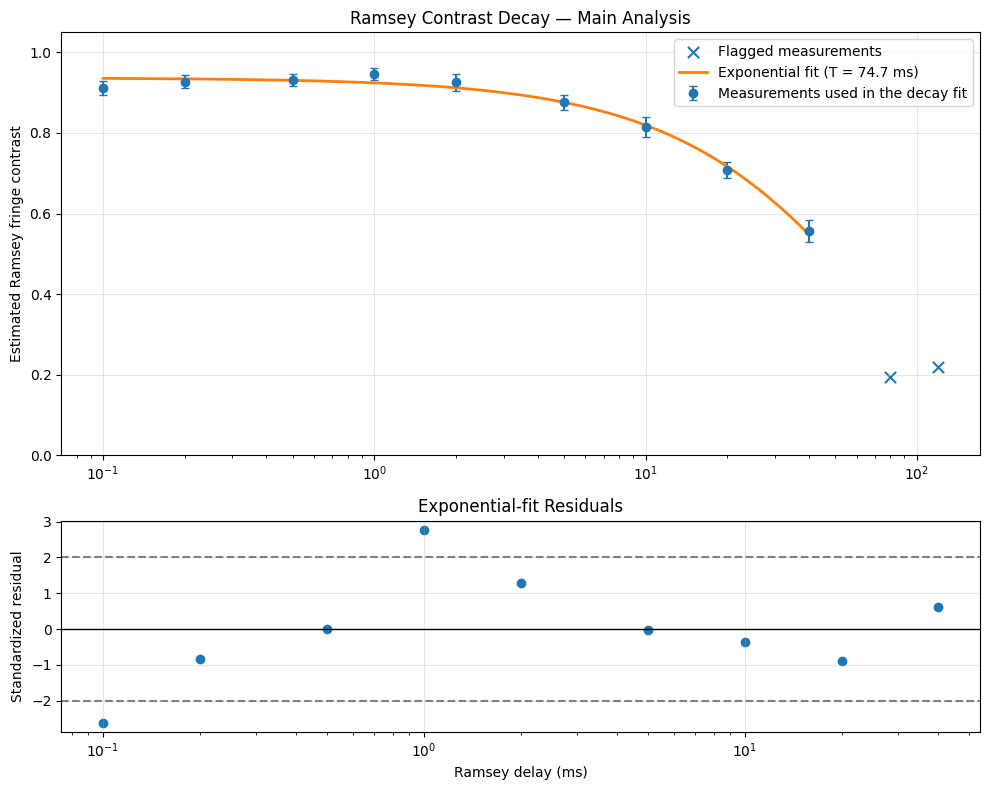


Saved figure to /content/ramsey_main_result.png


In [42]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

data = contrast_summary.copy().sort_values("Delay (ms)")

delay = data["Delay (ms)"].to_numpy(dtype=float)
contrast = data["Contrast"].to_numpy(dtype=float)
contrast_se = data["Approx. contrast SE"].to_numpy(dtype=float)
fringe_r_squared = data["R-squared"].to_numpy(dtype=float)

reliable = (
    (fringe_r_squared >= 0.90)
    & (delay <= 40)
)

fit_delay = delay[reliable]
fit_contrast = contrast[reliable]
fit_se = contrast_se[reliable]


def exponential_decay(time_ms, initial_contrast, decay_time_ms):
    return initial_contrast * np.exp(-time_ms / decay_time_ms)


parameters, covariance = curve_fit(
    exponential_decay,
    fit_delay,
    fit_contrast,
    sigma=fit_se,
    absolute_sigma=True,
    p0=[0.95, 75],
    bounds=([0.0, 0.1], [1.2, 1000]),
    maxfev=20000
)

initial_contrast, decay_time = parameters
decay_time_se = np.sqrt(covariance[1, 1])

predicted = exponential_decay(fit_delay, *parameters)
standardized_residuals = (fit_contrast - predicted) / fit_se

degrees_of_freedom = len(fit_delay) - len(parameters)
reduced_chi_squared = (
    np.sum(standardized_residuals ** 2) / degrees_of_freedom
)

print(f"Points used in the decay fit: {len(fit_delay)}")
print(f"Initial contrast: {initial_contrast:.4f}")
print(f"Exploratory decay time: {decay_time:.2f} ms")
print(
    "Approximate 95% interval: "
    f"{max(0, decay_time - 1.96 * decay_time_se):.2f}–"
    f"{decay_time + 1.96 * decay_time_se:.2f} ms"
)
print(f"Reduced chi-squared: {reduced_chi_squared:.2f}")

fig, axes = plt.subplots(
    2, 1,
    figsize=(10, 8),
    gridspec_kw={"height_ratios": [2, 1]}
)

axes[0].errorbar(
    delay[reliable],
    contrast[reliable],
    yerr=1.96 * contrast_se[reliable],
    fmt="o",
    capsize=3,
    label="Measurements used in the decay fit"
)

excluded = ~reliable

axes[0].scatter(
    delay[excluded],
    contrast[excluded],
    marker="x",
    s=65,
    label="Flagged measurements"
)

time_grid = np.linspace(fit_delay.min(), fit_delay.max(), 300)

axes[0].plot(
    time_grid,
    exponential_decay(time_grid, *parameters),
    linewidth=2,
    label=f"Exponential fit (T = {decay_time:.1f} ms)"
)

axes[0].set_xscale("log")
axes[0].set_ylabel("Estimated Ramsey fringe contrast")
axes[0].set_title("Ramsey Contrast Decay — Main Analysis")
axes[0].set_ylim(0, 1.05)
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].axhline(0, color="black", linewidth=1)
axes[1].axhline(2, color="gray", linestyle="--")
axes[1].axhline(-2, color="gray", linestyle="--")

axes[1].scatter(fit_delay, standardized_residuals)

axes[1].set_xscale("log")
axes[1].set_xlabel("Ramsey delay (ms)")
axes[1].set_ylabel("Standardized residual")
axes[1].set_title("Exponential-fit Residuals")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    "/content/ramsey_main_result.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\nSaved figure to /content/ramsey_main_result.png")


Calibration scans: 9
Shared empirical phase multiplier: 3.9940


,Delay (ms),Original points,Points fitted,Contrast,R-squared,Status
0,0.1,193,180,0.9124,0.9832,Fitted with shared multiplier
1,0.2,182,180,0.9270,0.9861,Fitted with shared multiplier
2,0.5,183,180,0.9307,0.9879,Fitted with shared multiplier
3,1.0,181,180,0.9472,0.9881,Fitted with shared multiplier
4,2.0,183,180,0.9272,0.9775,Fitted with shared multiplier
5,5.0,181,180,0.8763,0.9819,Fitted with shared multiplier
6,10.0,180,180,0.8140,0.9581,Fitted with shared multiplier
7,20.0,182,180,0.7082,0.9646,Fitted with shared multiplier
8,40.0,182,180,0.5570,0.9060,Fitted with shared multiplier
9,80.0,169,169,NaN,NaN,Incomplete scan — not fitted


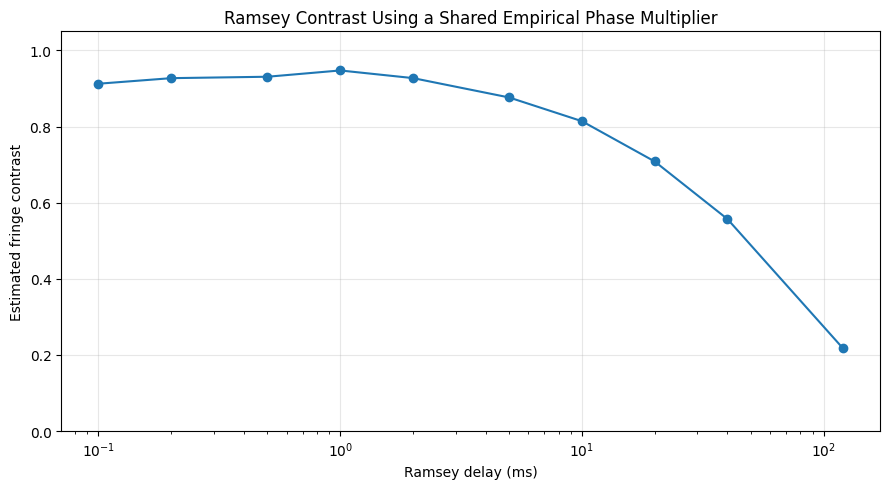

In [43]:

from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("/content/ramsey_data/Ramsey/0+1")
EXPECTED_POINTS = 180
PHASE_STEP_DEGREES = 2.0

filename_pattern = re.compile(
    r"step_2_delay_(?P<delay>[\d.]+)_ms\.xlsx$"
)

scans = []

for file_path in sorted(DATA_DIR.glob("step_2_delay_*_ms.xlsx")):
    match = filename_pattern.fullmatch(file_path.name)

    if match is None:
        continue

    data = pd.read_excel(file_path)
    probability = data["probability"].to_numpy(dtype=float)

    scans.append({
        "delay_ms": float(match.group("delay")),
        "file": file_path.name,
        "original_points": len(probability),
        "probability": probability
    })

scans.sort(key=lambda scan: scan["delay_ms"])

calibration_scans = [
    scan for scan in scans
    if (
        scan["delay_ms"] <= 40
        and scan["original_points"] >= EXPECTED_POINTS
    )
]

if not calibration_scans:
    raise ValueError("No complete calibration scans were found.")

phase_degrees = (
    np.arange(EXPECTED_POINTS) * PHASE_STEP_DEGREES
)

candidate_multipliers = np.linspace(3.5, 4.5, 1001)
best_calibration = None

for multiplier in candidate_multipliers:
    total_residual_sum = 0.0

    effective_phase = np.deg2rad(
        multiplier * phase_degrees
    )

    design_matrix = np.column_stack([
        np.ones(EXPECTED_POINTS),
        np.cos(effective_phase),
        np.sin(effective_phase)
    ])

    for scan in calibration_scans:
        probability = scan["probability"][:EXPECTED_POINTS]

        coefficients, *_ = np.linalg.lstsq(
            design_matrix,
            probability,
            rcond=None
        )

        residuals = probability - design_matrix @ coefficients
        total_residual_sum += np.sum(residuals ** 2)

    if (
        best_calibration is None
        or total_residual_sum < best_calibration["rss"]
    ):
        best_calibration = {
            "multiplier": multiplier,
            "rss": total_residual_sum
        }

shared_multiplier = best_calibration["multiplier"]

print(f"Calibration scans: {len(calibration_scans)}")
print(f"Shared empirical phase multiplier: {shared_multiplier:.4f}")

results = []

for scan in scans:
    if scan["original_points"] < EXPECTED_POINTS:
        results.append({
            "Delay (ms)": scan["delay_ms"],
            "Original points": scan["original_points"],
            "Points fitted": scan["original_points"],
            "Contrast": np.nan,
            "R-squared": np.nan,
            "Status": "Incomplete scan — not fitted"
        })
        continue

    probability = scan["probability"][:EXPECTED_POINTS]
    effective_phase = np.deg2rad(
        shared_multiplier * phase_degrees
    )

    design_matrix = np.column_stack([
        np.ones(EXPECTED_POINTS),
        np.cos(effective_phase),
        np.sin(effective_phase)
    ])

    coefficients, *_ = np.linalg.lstsq(
        design_matrix,
        probability,
        rcond=None
    )

    fitted = design_matrix @ coefficients
    residual_sum = np.sum((probability - fitted) ** 2)
    total_sum = np.sum(
        (probability - probability.mean()) ** 2
    )

    r_squared = (
        1 - residual_sum / total_sum
        if total_sum > 0 else np.nan
    )

    contrast = 2 * np.hypot(
        coefficients[1],
        coefficients[2]
    )

    results.append({
        "Delay (ms)": scan["delay_ms"],
        "Original points": scan["original_points"],
        "Points fitted": EXPECTED_POINTS,
        "Contrast": contrast,
        "R-squared": r_squared,
        "Status": "Fitted with shared multiplier"
    })

summary = pd.DataFrame(results).sort_values("Delay (ms)")
display(summary.round(4))

plt.figure(figsize=(9, 5))

complete_scans = summary[
    summary["Status"] == "Fitted with shared multiplier"
]

plt.plot(
    complete_scans["Delay (ms)"],
    complete_scans["Contrast"],
    "o-"
)

plt.xscale("log")
plt.xlabel("Ramsey delay (ms)")
plt.ylabel("Estimated fringe contrast")
plt.title("Ramsey Contrast Using a Shared Empirical Phase Multiplier")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [44]:

from pathlib import Path

import numpy as np
import pandas as pd

final_results = summary.copy().sort_values("Delay (ms)")

final_results["Phase multiplier"] = shared_multiplier

final_results["Main fit inclusion"] = (
    (final_results["R-squared"] >= 0.90)
    & (final_results["Delay (ms)"] <= 40)
    & (
        final_results["Status"]
        == "Fitted with shared multiplier"
    )
)

def review_note(row):
    if row["Status"] == "Incomplete scan — not fitted":
        return "Incomplete scan: review raw measurements"

    if row["R-squared"] < 0.90:
        return "Low fringe-fit quality: review before interpretation"

    if row["Main fit inclusion"]:
        return "Included in exploratory decay fit"

    return "Complete scan, outside primary fit interval"


final_results["Review note"] = final_results.apply(
    review_note,
    axis=1
)

output_dir = Path("/content/ramsey_results")
output_dir.mkdir(parents=True, exist_ok=True)

output_file = output_dir / "ramsey_contrast_summary.csv"

final_results.to_csv(output_file, index=False)

print("✅ Results table saved.")
print(f"File: {output_file}")
print(f"Total delay settings: {len(final_results)}")
print(
    "Included in primary exploratory fit:",
    int(final_results["Main fit inclusion"].sum())
)
print(
    "Flagged for review:",
    int((~final_results["Main fit inclusion"]).sum())
)

display(
    final_results[
        [
            "Delay (ms)",
            "Original points",
            "Points fitted",
            "Phase multiplier",
            "Contrast",
            "R-squared",
            "Main fit inclusion",
            "Review note"
        ]
    ].round(4)
)


✅ Results table saved.
File: /content/ramsey_results/ramsey_contrast_summary.csv
Total delay settings: 11
Included in primary exploratory fit: 9
Flagged for review: 2


,Delay (ms),Original points,Points fitted,Phase multiplier,Contrast,R-squared,Main fit inclusion,Review note
0,0.1,193,180,3.994,0.9124,0.9832,True,Included in exploratory decay fit
1,0.2,182,180,3.994,0.9270,0.9861,True,Included in exploratory decay fit
2,0.5,183,180,3.994,0.9307,0.9879,True,Included in exploratory decay fit
3,1.0,181,180,3.994,0.9472,0.9881,True,Included in exploratory decay fit
4,2.0,183,180,3.994,0.9272,0.9775,True,Included in exploratory decay fit
5,5.0,181,180,3.994,0.8763,0.9819,True,Included in exploratory decay fit
6,10.0,180,180,3.994,0.8140,0.9581,True,Included in exploratory decay fit
7,20.0,182,180,3.994,0.7082,0.9646,True,Included in exploratory decay fit
8,40.0,182,180,3.994,0.5570,0.9060,True,Included in exploratory decay fit
9,80.0,169,169,3.994,NaN,NaN,False,Incomplete scan: review raw measurements


,Delay (ms),Original points,Points analyzed,Contrast,Contrast SE,R-squared,Use in decay fit
0,0.1,193,180,0.9124,0.0090,0.9832,True
1,0.2,182,180,0.9270,0.0083,0.9861,True
2,0.5,183,180,0.9307,0.0077,0.9879,True
3,1.0,181,180,0.9472,0.0078,0.9881,True
4,2.0,183,180,0.9272,0.0106,0.9775,True
5,5.0,181,180,0.8763,0.0089,0.9819,True
6,10.0,180,180,0.8140,0.0128,0.9581,True
7,20.0,182,180,0.7082,0.0102,0.9646,True
8,40.0,182,180,0.5570,0.0135,0.9060,True
9,80.0,169,169,0.1912,0.0262,0.2434,False



Final exploratory decay fit:


,Points fitted,Phase multiplier,Initial contrast,Decay time (ms),Approx. decay-time SE (ms),Approx. 95% CI lower (ms),Approx. 95% CI upper (ms),Reduced chi-squared
0,9,3.994,0.9373,74.6696,2.7067,69.3644,79.9748,2.7588


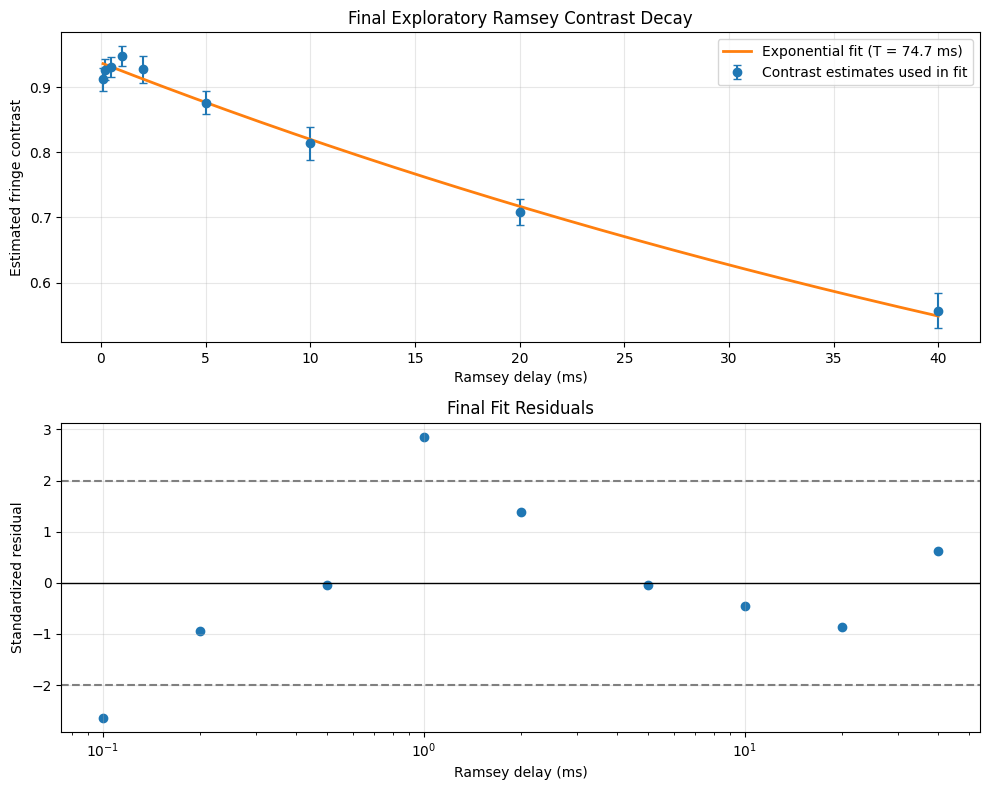


Final tables saved in: /content/ramsey_results


In [45]:

from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

DATA_DIR = Path("/content/ramsey_data/Ramsey/0+1")

EXPECTED_POINTS = 180
PHASE_STEP_DEGREES = 2.0
PHASE_MULTIPLIER = 3.994

filename_pattern = re.compile(
    r"step_2_delay_(?P<delay>[\d.]+)_ms\.xlsx$"
)


def estimate_contrast(probability):
    point_count = len(probability)

    phase_degrees = (
        np.arange(point_count) * PHASE_STEP_DEGREES
    )
    effective_phase = np.deg2rad(
        PHASE_MULTIPLIER * phase_degrees
    )

    design_matrix = np.column_stack([
        np.ones(point_count),
        np.cos(effective_phase),
        np.sin(effective_phase)
    ])

    coefficients, *_ = np.linalg.lstsq(
        design_matrix,
        probability,
        rcond=None
    )

    fitted_probability = design_matrix @ coefficients
    residuals = probability - fitted_probability

    residual_sum = np.sum(residuals ** 2)
    total_sum = np.sum(
        (probability - probability.mean()) ** 2
    )

    r_squared = (
        1 - residual_sum / total_sum
        if total_sum > 0 else np.nan
    )

    degrees_of_freedom = point_count - design_matrix.shape[1]
    residual_variance = residual_sum / degrees_of_freedom

    coefficient_covariance = residual_variance * np.linalg.inv(
        design_matrix.T @ design_matrix
    )

    cosine_term = coefficients[1]
    sine_term = coefficients[2]

    amplitude = np.hypot(cosine_term, sine_term)
    contrast = 2 * amplitude

    if amplitude > 0:
        gradient = 2 * np.array([
            cosine_term / amplitude,
            sine_term / amplitude
        ])

        contrast_variance = (
            gradient
            @ coefficient_covariance[1:3, 1:3]
            @ gradient
        )

        contrast_se = np.sqrt(max(contrast_variance, 0))
    else:
        contrast_se = np.nan

    return contrast, contrast_se, r_squared


records = []

for file_path in sorted(DATA_DIR.glob("step_2_delay_*_ms.xlsx")):
    match = filename_pattern.fullmatch(file_path.name)

    if match is None:
        continue

    data = pd.read_excel(file_path)
    original_probability = data["probability"].to_numpy(dtype=float)

    point_count = min(len(original_probability), EXPECTED_POINTS)
    probability = original_probability[:point_count]

    contrast, contrast_se, r_squared = estimate_contrast(probability)

    complete_scan = len(original_probability) >= EXPECTED_POINTS
    acceptable_fit = r_squared >= 0.90

    records.append({
        "Delay (ms)": float(match.group("delay")),
        "Original points": len(original_probability),
        "Points analyzed": point_count,
        "Contrast": contrast,
        "Contrast SE": contrast_se,
        "R-squared": r_squared,
        "Use in decay fit": (
            complete_scan
            and acceptable_fit
            and float(match.group("delay")) <= 40
        )
    })

final_contrast_table = (
    pd.DataFrame(records)
    .sort_values("Delay (ms)")
    .reset_index(drop=True)
)

display(final_contrast_table.round(4))

fit_data = final_contrast_table[
    final_contrast_table["Use in decay fit"]
].copy()

delay = fit_data["Delay (ms)"].to_numpy(dtype=float)
contrast = fit_data["Contrast"].to_numpy(dtype=float)
contrast_se = fit_data["Contrast SE"].to_numpy(dtype=float)


def exponential_decay(time_ms, initial_contrast, decay_time_ms):
    return initial_contrast * np.exp(-time_ms / decay_time_ms)


parameters, covariance = curve_fit(
    exponential_decay,
    delay,
    contrast,
    sigma=contrast_se,
    absolute_sigma=True,
    p0=[0.95, 75],
    bounds=([0.0, 0.1], [1.2, 1000]),
    maxfev=20000
)

initial_contrast, decay_time = parameters
parameter_se = np.sqrt(np.diag(covariance))

predicted = exponential_decay(delay, *parameters)
standardized_residuals = (contrast - predicted) / contrast_se

degrees_of_freedom = len(delay) - len(parameters)
chi_squared = np.sum(standardized_residuals ** 2)
reduced_chi_squared = chi_squared / degrees_of_freedom

final_metrics = pd.DataFrame([{
    "Points fitted": len(delay),
    "Phase multiplier": PHASE_MULTIPLIER,
    "Initial contrast": initial_contrast,
    "Decay time (ms)": decay_time,
    "Approx. decay-time SE (ms)": parameter_se[1],
    "Approx. 95% CI lower (ms)": max(
        0, decay_time - 1.96 * parameter_se[1]
    ),
    "Approx. 95% CI upper (ms)": (
        decay_time + 1.96 * parameter_se[1]
    ),
    "Reduced chi-squared": reduced_chi_squared
}])

print("\nFinal exploratory decay fit:")
display(final_metrics.round(4))

fig, axes = plt.subplots(2, 1, figsize=(10, 8))

time_grid = np.linspace(delay.min(), delay.max(), 300)

axes[0].errorbar(
    delay,
    contrast,
    yerr=1.96 * contrast_se,
    fmt="o",
    capsize=3,
    label="Contrast estimates used in fit"
)

axes[0].plot(
    time_grid,
    exponential_decay(time_grid, *parameters),
    linewidth=2,
    label=f"Exponential fit (T = {decay_time:.1f} ms)"
)

axes[0].set_xlabel("Ramsey delay (ms)")
axes[0].set_ylabel("Estimated fringe contrast")
axes[0].set_title("Final Exploratory Ramsey Contrast Decay")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].axhline(0, color="black", linewidth=1)
axes[1].axhline(2, color="gray", linestyle="--")
axes[1].axhline(-2, color="gray", linestyle="--")

axes[1].scatter(delay, standardized_residuals)
axes[1].set_xscale("log")
axes[1].set_xlabel("Ramsey delay (ms)")
axes[1].set_ylabel("Standardized residual")
axes[1].set_title("Final Fit Residuals")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

output_dir = Path("/content/ramsey_results")
output_dir.mkdir(parents=True, exist_ok=True)

final_contrast_table.to_csv(
    output_dir / "ramsey_final_contrast_table.csv",
    index=False
)
final_metrics.to_csv(
    output_dir / "ramsey_final_decay_metrics.csv",
    index=False
)

print(f"\nFinal tables saved in: {output_dir}")
